
# ADÉLIA — Preparação dos Dados para Modelagem Preditiva

## Objetivo

Este notebook tem como objetivo preparar e analisar os dados históricos de vendas da ADÉLIA para o desenvolvimento de modelos preditivos.

A primeira etapa da modelagem será direcionada à previsão da demanda semanal por produto, utilizando a quantidade de unidades vendidas como variável-alvo.

Serão avaliados os 36 produtos presentes na base de dados, considerando:

- Agregação das vendas por produto e semana;
- Construção de um calendário semanal completo;
- Identificação de semanas sem vendas;
- Análise da frequência e da variabilidade da demanda;
- Avaliação da viabilidade de previsão individual por produto.

Os horizontes iniciais de previsão serão de 4 e 8 semanas.

**Importante:** a ausência de vendas em uma semana não significa necessariamente ausência de dados. Por isso, a cobertura temporal será verificada antes de preencher períodos com zero.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))


## 1. Carregamento e Conferência dos Dados

Nesta etapa, serão carregadas as cinco tabelas que compõem a base de dados da ADÉLIA.

O carregamento será realizado diretamente a partir da pasta DATA, mantendo este notebook independente das variáveis utilizadas na análise exploratória anterior.

Após a leitura, serão verificadas as dimensões das tabelas para confirmar se os dados foram carregados corretamente.


In [7]:

# Localiza a pasta DATA, considerando possíveis diretórios de execução

caminhos_data = [
    Path.cwd() / "DATA",
    Path.cwd().parent / "DATA"
]

pasta_data = next(
    (caminho for caminho in caminhos_data if caminho.exists()),
    None
)

if pasta_data is None:
    raise FileNotFoundError(
        "Não foi possível localizar a pasta DATA."
    )

print("Pasta de dados localizada em:", pasta_data.resolve())


# Carregamento das tabelas

produtos = pd.read_csv(pasta_data / "produtos.csv")
clientes = pd.read_csv(pasta_data / "clientes.csv")
vendas = pd.read_csv(pasta_data / "vendas.csv")
itens_venda = pd.read_csv(pasta_data / "itens_venda.csv")
estoque = pd.read_csv(pasta_data / "estoque.csv")


# Conferência das dimensões

tabelas = {
    "Produtos": produtos,
    "Clientes": clientes,
    "Vendas": vendas,
    "Itens de venda": itens_venda,
    "Estoque": estoque
}

for nome, tabela in tabelas.items():
    print(f"{nome}: {tabela.shape[0]} linhas e {tabela.shape[1]} colunas")


Pasta de dados localizada em: C:\Users\danri\Documents\ADÉLIArpz\ADELIA\DATA
Produtos: 36 linhas e 6 colunas
Clientes: 650 linhas e 6 colunas
Vendas: 5000 linhas e 5 colunas
Itens de venda: 9230 linhas e 7 colunas
Estoque: 36 linhas e 4 colunas



### 2.1. Preparação das Datas e Relacionamentos

Para identificar a semana de cada venda, será necessário relacionar a tabela de itens de venda com a tabela de vendas.

Também serão incorporados os nomes dos produtos para facilitar a interpretação dos resultados.

As datas serão convertidas para o formato datetime, permitindo operações temporais.


In [8]:

# Conversão da coluna de data

vendas["data_venda"] = pd.to_datetime(
    vendas["data_venda"],
    errors="coerce"
)

# Verificação de datas inválidas

datas_invalidas = vendas["data_venda"].isna().sum()

print("Datas inválidas:", datas_invalidas)

if datas_invalidas > 0:
    raise ValueError("Existem datas inválidas na tabela de vendas.")


# Relacionamento entre itens de venda e vendas

itens_com_data = itens_venda.merge(
    vendas[["venda_id", "data_venda"]],
    on="venda_id",
    how="left",
    validate="many_to_one"
)

# Relacionamento com os produtos

itens_com_data = itens_com_data.merge(
    produtos[["produto_id", "nome_produto"]],
    on="produto_id",
    how="left",
    validate="many_to_one"
)

print("Registros após os relacionamentos:", len(itens_com_data))
print("Datas ausentes após os relacionamentos:", itens_com_data["data_venda"].isna().sum())


Datas inválidas: 0
Registros após os relacionamentos: 9230
Datas ausentes após os relacionamentos: 0



### 2.2. Identificação das Semanas

Cada venda será associada à segunda-feira da semana em que ocorreu.

Essa padronização permitirá agrupar as quantidades vendidas em intervalos semanais, mantendo uma estrutura adequada para análises temporais e previsões.


In [9]:

# Identifica a segunda-feira de cada semana

itens_com_data["inicio_semana"] = (
    itens_com_data["data_venda"]
    - pd.to_timedelta(
        itens_com_data["data_venda"].dt.weekday,
        unit="D"
    )
)

# Conferência

print("Primeira data de venda:", itens_com_data["data_venda"].min())
print("Última data de venda:", itens_com_data["data_venda"].max())

print("\nExemplo de datas e semanas correspondentes:")

display(
    itens_com_data[
        ["data_venda", "inicio_semana", "produto_id", "nome_produto", "quantidade"]
    ].head(10)
)


Primeira data de venda: 2024-01-01 00:00:00
Última data de venda: 2026-10-31 00:00:00

Exemplo de datas e semanas correspondentes:


,data_venda,inicio_semana,produto_id,nome_produto,quantidade
0,2024-01-01,2024-01-01,P001,Notebook Start 14,1
1,2024-01-01,2024-01-01,P028,Cabo USB-C 1m,1
2,2024-01-01,2024-01-01,P027,Carregador USB-C,3
3,2024-01-01,2024-01-01,P035,SSD Externo 1 TB,1
4,2024-01-01,2024-01-01,P034,Pendrive 64 GB,1
5,2024-01-01,2024-01-01,P021,Monitor LED 24,1
6,2024-01-01,2024-01-01,P035,SSD Externo 1 TB,1
7,2024-01-02,2024-01-01,P023,Teclado Mecânico,1
8,2024-01-02,2024-01-01,P001,Notebook Start 14,1
9,2024-01-02,2024-01-01,P030,Película de Proteção,2



### 2.3. Agregação da Demanda Semanal por Produto

Nesta etapa, os registros serão agrupados por produto e semana.

A variável quantidade será somada para representar o total de unidades vendidas de cada produto em cada semana.

O resultado será uma tabela histórica de demanda semanal, que servirá como base para as próximas análises.


In [10]:

# Agrupamento por produto e semana

demanda_semanal = (
    itens_com_data
    .groupby(
        ["produto_id", "nome_produto", "inicio_semana"],
        as_index=False
    )["quantidade"]
    .sum()
)

# Ordenação dos registros

demanda_semanal = demanda_semanal.sort_values(
    ["produto_id", "inicio_semana"]
).reset_index(drop=True)


# Conferência do resultado

print("Total de registros semanais:", len(demanda_semanal))
print("Produtos identificados:", demanda_semanal["produto_id"].nunique())
print("Primeira semana:", demanda_semanal["inicio_semana"].min())
print("Última semana:", demanda_semanal["inicio_semana"].max())

display(demanda_semanal.head(15))


Total de registros semanais: 4278
Produtos identificados: 36
Primeira semana: 2024-01-01 00:00:00
Última semana: 2026-10-26 00:00:00


,produto_id,nome_produto,inicio_semana,quantidade
0,P001,Notebook Start 14,2024-01-01,3
1,P001,Notebook Start 14,2024-01-22,1
2,P001,Notebook Start 14,2024-01-29,2
3,P001,Notebook Start 14,2024-02-05,1
4,P001,Notebook Start 14,2024-02-26,1
5,P001,Notebook Start 14,2024-03-04,1
6,P001,Notebook Start 14,2024-03-11,2
7,P001,Notebook Start 14,2024-03-18,3
8,P001,Notebook Start 14,2024-03-25,2
9,P001,Notebook Start 14,2024-04-01,3



## 3. Construção do Calendário Semanal Completo

A agregação anterior apresenta somente as semanas em que houve vendas.

Para preparar os dados para modelagem preditiva, será construído um calendário semanal completo para cada produto.

As semanas sem vendas registradas serão preenchidas com zero, permitindo identificar a frequência e a ausência de demanda.

A última semana do histórico será tratada separadamente, pois não possui cobertura completa até domingo.


In [11]:

# Identificação do período histórico

primeira_semana = demanda_semanal["inicio_semana"].min()

ultima_semana_registrada = demanda_semanal["inicio_semana"].max()

# Identifica a última semana completamente observada
# Se o último dia disponível não for domingo, exclui a semana em andamento.

ultima_data = vendas["data_venda"].max()

inicio_ultima_semana = ultima_data - pd.Timedelta(
    days=ultima_data.weekday()
)

if ultima_data.weekday() == 6:
    ultima_semana_completa = inicio_ultima_semana
else:
    ultima_semana_completa = inicio_ultima_semana - pd.Timedelta(days=7)


print("Primeira semana:", primeira_semana.date())
print("Última semana registrada:", ultima_semana_registrada.date())
print("Última semana completa:", ultima_semana_completa.date())
print("Última data disponível:", ultima_data.date())


Primeira semana: 2024-01-01
Última semana registrada: 2026-10-26
Última semana completa: 2026-10-19
Última data disponível: 2026-10-31


In [12]:

# Remove a semana incompleta da base agregada

demanda_periodo_completo = demanda_semanal[
    demanda_semanal["inicio_semana"] <= ultima_semana_completa
].copy()


# Criação do calendário semanal

calendario_semanal = pd.date_range(
    start=primeira_semana,
    end=ultima_semana_completa,
    freq="W-MON"
)


# Identificação dos produtos

cadastro_produtos = produtos[
    ["produto_id", "nome_produto"]
].drop_duplicates()


# Combinação de todos os produtos com todas as semanas

calendario_produtos = cadastro_produtos.merge(
    pd.DataFrame({"inicio_semana": calendario_semanal}),
    how="cross"
)


print("Quantidade de semanas completas:", len(calendario_semanal))
print("Quantidade de produtos:", len(cadastro_produtos))
print("Total esperado de combinações:", len(calendario_produtos))


Quantidade de semanas completas: 147
Quantidade de produtos: 36
Total esperado de combinações: 5292


In [13]:

# Relacionamento entre calendário e demanda observada

demanda_completa = calendario_produtos.merge(
    demanda_periodo_completo[
        ["produto_id", "inicio_semana", "quantidade"]
    ],
    on=["produto_id", "inicio_semana"],
    how="left",
    validate="one_to_one"
)


# Preenchimento das semanas sem vendas registradas

demanda_completa["quantidade"] = (
    demanda_completa["quantidade"]
    .fillna(0)
    .astype(int)
)


# Organização dos registros

demanda_completa = demanda_completa.sort_values(
    ["produto_id", "inicio_semana"]
).reset_index(drop=True)


# Conferência

print("Total de registros:", len(demanda_completa))
print("Produtos:", demanda_completa["produto_id"].nunique())
print("Semanas:", demanda_completa["inicio_semana"].nunique())
print("Registros com quantidade zero:", (demanda_completa["quantidade"] == 0).sum())

display(demanda_completa.head(20))


Total de registros: 5292
Produtos: 36
Semanas: 147
Registros com quantidade zero: 1048


,produto_id,nome_produto,inicio_semana,quantidade
0,P001,Notebook Start 14,2024-01-01,3
1,P001,Notebook Start 14,2024-01-08,0
2,P001,Notebook Start 14,2024-01-15,0
3,P001,Notebook Start 14,2024-01-22,1
4,P001,Notebook Start 14,2024-01-29,2
5,P001,Notebook Start 14,2024-02-05,1
6,P001,Notebook Start 14,2024-02-12,0
7,P001,Notebook Start 14,2024-02-19,0
8,P001,Notebook Start 14,2024-02-26,1
9,P001,Notebook Start 14,2024-03-04,1



## 4. Diagnóstico do Comportamento da Demanda

Nesta etapa, será analisada a distribuição das vendas semanais de cada produto.

O objetivo é identificar diferenças na frequência e na variabilidade da demanda, verificando quais produtos apresentam vendas frequentes e quais possuem comportamento mais intermitente.

Serão utilizados indicadores estatísticos como frequência de vendas, intervalo médio entre demandas (ADI) e coeficiente de variação ao quadrado (CV²).

Essas informações ajudarão a avaliar quais abordagens de previsão são mais adequadas para cada produto.


In [14]:

# Quantidade total de semanas analisadas
total_semanas = demanda_completa["inicio_semana"].nunique()


# Função para calcular os indicadores de cada produto

def calcular_diagnostico(grupo):

    quantidades = grupo["quantidade"]

    semanas_com_vendas = (quantidades > 0).sum()
    semanas_sem_vendas = (quantidades == 0).sum()

    quantidade_total = quantidades.sum()

    # Média considerando todas as semanas, inclusive zeros
    media_semanal = quantidades.mean()

    # Valores somente das semanas com vendas
    demanda_positiva = quantidades[quantidades > 0]

    media_positiva = demanda_positiva.mean()

    desvio_positivo = demanda_positiva.std(ddof=0)

    # Intervalo médio entre semanas com demanda
    if semanas_com_vendas > 0:
        adi = total_semanas / semanas_com_vendas
    else:
        adi = np.nan

    # Coeficiente de variação ao quadrado
    if media_positiva > 0:
        cv2 = (desvio_positivo / media_positiva) ** 2
    else:
        cv2 = np.nan

    return pd.Series({
        "semanas_analisadas": len(grupo),
        "semanas_com_vendas": semanas_com_vendas,
        "semanas_sem_vendas": semanas_sem_vendas,
        "frequencia_vendas_pct": (
            semanas_com_vendas / len(grupo) * 100
        ),
        "quantidade_total": quantidade_total,
        "media_semanal": media_semanal,
        "media_positiva": media_positiva,
        "adi": adi,
        "cv2": cv2
    })


# Aplicação do diagnóstico aos 36 produtos

diagnostico_produtos = (
    demanda_completa
    .groupby(["produto_id", "nome_produto"])
    .apply(calcular_diagnostico, include_groups=False)
    .reset_index()
)


# Ordenação pela frequência de vendas

diagnostico_produtos = diagnostico_produtos.sort_values(
    "frequencia_vendas_pct",
    ascending=False
).reset_index(drop=True)


display(diagnostico_produtos)


,produto_id,nome_produto,semanas_analisadas,semanas_com_vendas,semanas_sem_vendas,frequencia_vendas_pct,quantidade_total,media_semanal,media_positiva,adi,cv2
0,P022,Monitor Gamer 27,"147,00","141,00","6,00","95,92","526,00","3,58","3,73","1,04","0,36"
1,P025,Headset USB,"147,00","137,00","10,00","93,20","454,00","3,09","3,31","1,07","0,33"
2,P024,Mouse Gamer,"147,00","136,00","11,00","92,52","461,00","3,14","3,39","1,08","0,33"
3,P008,Smartphone Plus B,"147,00","136,00","11,00","92,52","377,00","2,56","2,77","1,08","0,31"
4,P023,Teclado Mecânico,"147,00","133,00","14,00","90,48","376,00","2,56","2,83","1,11","0,30"
5,P011,Smartphone Max E,"147,00","132,00","15,00","89,80","332,00","2,26","2,52","1,11","0,26"
6,P029,Capa para Smartphone,"147,00","132,00","15,00","89,80","508,00","3,46","3,85","1,11","0,42"
7,P034,Pendrive 64 GB,"147,00","130,00","17,00","88,44","464,00","3,16","3,57","1,13","0,58"
8,P021,Monitor LED 24,"147,00","130,00","17,00","88,44","357,00","2,43","2,75","1,13","0,32"
9,P030,Película de Proteção,"147,00","127,00","20,00","86,39","437,00","2,97","3,44","1,16","0,40"


In [15]:
# Funções de formatação brasileira

def formatar_inteiro(valor):
    return f"{valor:,.0f}".replace(",", ".")


def formatar_percentual(valor):
    return f"{valor:.2f}%".replace(".", ",")

In [16]:

# Resumo geral do comportamento da demanda

print("PRODUTOS ANALISADOS:", len(diagnostico_produtos))

print(
    "\nProdutos com vendas em todas as semanas:",
    (diagnostico_produtos["semanas_sem_vendas"] == 0).sum()
)

print(
    "Produtos sem vendas em nenhuma semana:",
    (diagnostico_produtos["semanas_com_vendas"] == 0).sum()
)

print(
    "Total de semanas sem vendas:",
    diagnostico_produtos["semanas_sem_vendas"].sum()
)

print(
    "Total de unidades vendidas:",
    formatar_inteiro(diagnostico_produtos["quantidade_total"].sum())
)

print(
    "\nMédia geral da frequência de vendas:",
    formatar_percentual(
        diagnostico_produtos["frequencia_vendas_pct"].mean()
    )
)


PRODUTOS ANALISADOS: 36

Produtos com vendas em todas as semanas: 0
Produtos sem vendas em nenhuma semana: 0
Total de semanas sem vendas: 1048.0
Total de unidades vendidas: 10.911

Média geral da frequência de vendas: 80,20%



### 4.1. Classificação Estatística da Demanda

Os produtos serão classificados de acordo com os indicadores ADI e CV², utilizando os limites convencionais do método de Syntetos–Boylan.

Essa classificação permitirá identificar diferentes padrões de comportamento da demanda e orientar a seleção das abordagens de previsão.


In [17]:

# Limites utilizados na classificação

limite_adi = 1.32
limite_cv2 = 0.49


# Condições para classificação

condicoes = [
    (diagnostico_produtos["adi"] < limite_adi) &
    (diagnostico_produtos["cv2"] < limite_cv2),

    (diagnostico_produtos["adi"] < limite_adi) &
    (diagnostico_produtos["cv2"] >= limite_cv2),

    (diagnostico_produtos["adi"] >= limite_adi) &
    (diagnostico_produtos["cv2"] < limite_cv2),

    (diagnostico_produtos["adi"] >= limite_adi) &
    (diagnostico_produtos["cv2"] >= limite_cv2)
]


# Categorias correspondentes

categorias = [
    "Suave",
    "Errática",
    "Intermitente",
    "Irregular"
]


# Aplicação da classificação

diagnostico_produtos["classificacao_demanda"] = np.select(
    condicoes,
    categorias,
    default="Não classificada"
)


# Visualização dos resultados

display(
    diagnostico_produtos[
        [
            "produto_id",
            "nome_produto",
            "adi",
            "cv2",
            "classificacao_demanda"
        ]
    ]
)


,produto_id,nome_produto,adi,cv2,classificacao_demanda
0,P022,Monitor Gamer 27,"1,04","0,36",Suave
1,P025,Headset USB,"1,07","0,33",Suave
2,P024,Mouse Gamer,"1,08","0,33",Suave
3,P008,Smartphone Plus B,"1,08","0,31",Suave
4,P023,Teclado Mecânico,"1,11","0,30",Suave
5,P011,Smartphone Max E,"1,11","0,26",Suave
6,P029,Capa para Smartphone,"1,11","0,42",Suave
7,P034,Pendrive 64 GB,"1,13","0,58",Errática
8,P021,Monitor LED 24,"1,13","0,32",Suave
9,P030,Película de Proteção,"1,16","0,40",Suave


In [18]:

# Contagem de produtos por comportamento de demanda

resumo_classificacao = (
    diagnostico_produtos["classificacao_demanda"]
    .value_counts()
    .reindex(categorias, fill_value=0)
    .reset_index()
)

resumo_classificacao.columns = [
    "classificacao_demanda",
    "quantidade_produtos"
]

resumo_classificacao["percentual"] = (
    resumo_classificacao["quantidade_produtos"]
    / len(diagnostico_produtos) * 100
)

display(resumo_classificacao)


,classificacao_demanda,quantidade_produtos,percentual
0,Suave,24,"66,67"
1,Errática,1,"2,78"
2,Intermitente,10,"27,78"
3,Irregular,1,"2,78"


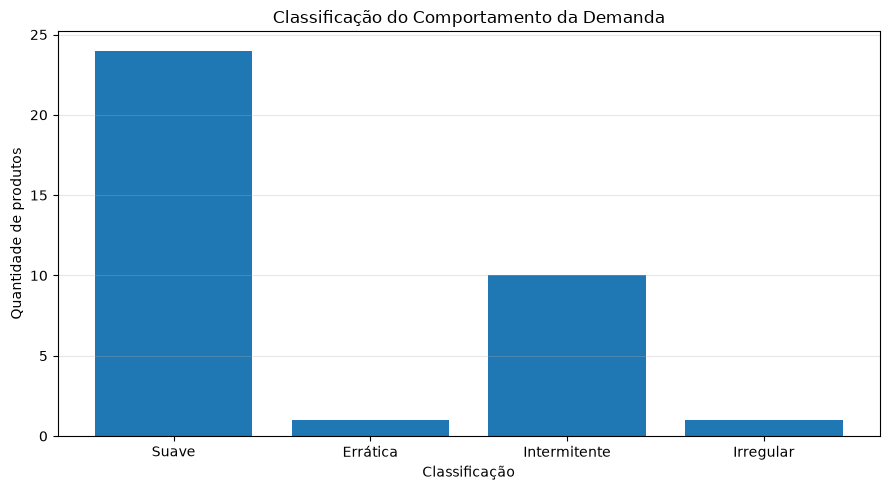

In [19]:

plt.figure(figsize=(9, 5))

plt.bar(
    resumo_classificacao["classificacao_demanda"],
    resumo_classificacao["quantidade_produtos"]
)

plt.title("Classificação do Comportamento da Demanda")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de produtos")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



## 5. Conclusão da Preparação e Diagnóstico da Demanda

A preparação dos dados resultou em uma base histórica semanal composta por 36 produtos e 147 semanas completas, totalizando 5.292 registros de produto-semana.

Foram identificados 1.048 registros sem vendas, correspondentes a aproximadamente 19,80% das combinações analisadas.

A classificação estatística baseada nos indicadores ADI e CV² identificou quatro comportamentos:

- Demanda suave: 24 produtos (66,67%);
- Demanda errática: 1 produto (2,78%);
- Demanda intermitente: 10 produtos (27,78%);
- Demanda irregular: 1 produto (2,78%).

Os resultados demonstram que os produtos apresentam diferentes padrões de comportamento da demanda. Portanto, a etapa de modelagem deverá considerar abordagens distintas e comparar seus desempenhos individualmente.

A base preparada será utilizada para desenvolver e avaliar modelos de previsão de demanda semanal, considerando inicialmente horizontes de 4 e 8 semanas.

**Limitação:** a classificação descreve o comportamento observado no histórico disponível e não garante a precisão de qualquer modelo preditivo. Além disso, os dados de estoque representam apenas uma fotografia em 31/10/2026, não permitindo reconstruir a disponibilidade histórica dos produtos.



## 6. Protocolo de Avaliação e Modelos de Referência

A avaliação dos modelos será realizada por meio de validação temporal com janela expansiva (*expanding window*).

O procedimento utiliza 95 semanas iniciais para treinamento. A cada rodada, o período de treinamento é ampliado e o modelo é avaliado em semanas posteriores, sem utilizar informações futuras durante o treinamento.

Serão considerados dois horizontes de previsão:

- 4 semanas;
- 8 semanas.

Para estabelecer referências de desempenho, serão implementados três métodos:

- **Naive:** utiliza a última quantidade observada como previsão para todas as semanas futuras.
- **Média móvel:** utiliza a média das quatro últimas semanas observadas.
- **Sazonal ingênuo:** utiliza a quantidade observada na mesma semana, 52 semanas antes.

Esses métodos servirão como referência para avaliar se modelos mais complexos conseguem melhorar a previsão de demanda.

No horizonte de 8 semanas, seis avaliações completas cobrem 48 das 52 semanas disponíveis após o treinamento inicial. As quatro semanas restantes não serão utilizadas nessa configuração.


In [20]:

# Modelos de referência e geração das previsões

previsoes = []

semanas = sorted(demanda_completa["inicio_semana"].unique())
produtos_ids = demanda_completa["produto_id"].unique()

semanas_iniciais_treino = 95
horizontes = [4, 8]

for horizonte in horizontes:

    inicio_avaliacao = semanas_iniciais_treino

    numero_avaliacao = 1

    while inicio_avaliacao + horizonte <= len(semanas):

        semanas_treino = semanas[:inicio_avaliacao]

        semanas_teste = semanas[
            inicio_avaliacao:inicio_avaliacao + horizonte
        ]

        treino = demanda_completa[
            demanda_completa["inicio_semana"].isin(semanas_treino)
        ]

        teste = demanda_completa[
            demanda_completa["inicio_semana"].isin(semanas_teste)
        ]

        for produto_id in produtos_ids:

            historico = (
                treino[treino["produto_id"] == produto_id]
                .sort_values("inicio_semana")
            )

            dados_teste = (
                teste[teste["produto_id"] == produto_id]
                .sort_values("inicio_semana")
            )

            # Modelo 1: Naive
            previsao_naive = historico["quantidade"].iloc[-1]

            # Modelo 2: Média móvel das últimas 4 semanas
            previsao_media = historico["quantidade"].tail(4).mean()

            # Histórico para o modelo sazonal
            historico_por_semana = dict(
                zip(
                    historico["inicio_semana"],
                    historico["quantidade"]
                )
            )

            for _, linha in dados_teste.iterrows():

                semana_teste = linha["inicio_semana"]
                quantidade_real = linha["quantidade"]

                semana_anterior_ano = (
                    semana_teste - pd.Timedelta(weeks=52)
                )

                previsao_sazonal = historico_por_semana.get(
                    semana_anterior_ano,
                    np.nan
                )

                previsoes.extend([
                    {
                        "produto_id": produto_id,
                        "horizonte": horizonte,
                        "avaliacao": numero_avaliacao,
                        "semana": semana_teste,
                        "modelo": "Naive",
                        "quantidade_real": quantidade_real,
                        "previsao": previsao_naive
                    },
                    {
                        "produto_id": produto_id,
                        "horizonte": horizonte,
                        "avaliacao": numero_avaliacao,
                        "semana": semana_teste,
                        "modelo": "Media movel 4 semanas",
                        "quantidade_real": quantidade_real,
                        "previsao": previsao_media
                    },
                    {
                        "produto_id": produto_id,
                        "horizonte": horizonte,
                        "avaliacao": numero_avaliacao,
                        "semana": semana_teste,
                        "modelo": "Sazonal ingenuo 52 semanas",
                        "quantidade_real": quantidade_real,
                        "previsao": previsao_sazonal
                    }
                ])

        inicio_avaliacao += horizonte
        numero_avaliacao += 1


previsoes_referencia = pd.DataFrame(previsoes)

print("Previsões de referência geradas!")
print(f"Total de registros: {len(previsoes_referencia)}")
print(f"Produtos avaliados: {previsoes_referencia['produto_id'].nunique()}")

print("\nRegistros por horizonte:")
display(previsoes_referencia["horizonte"].value_counts().sort_index())

print("\nRegistros por modelo:")
display(previsoes_referencia["modelo"].value_counts())


Previsões de referência geradas!
Total de registros: 10800
Produtos avaliados: 36

Registros por horizonte:


horizonte
4    5616
8    5184
Name: count, dtype: int64


Registros por modelo:


modelo
Naive                         3600
Media movel 4 semanas         3600
Sazonal ingenuo 52 semanas    3600
Name: count, dtype: int64

In [21]:

# Verificação das previsões de referência

print("VALORES AUSENTES")
display(
    previsoes_referencia.groupby("modelo")["previsao"]
    .apply(lambda serie: serie.isna().sum())
)

print("\nCOBERTURA DAS PREVISÕES")

resumo_previsoes = (
    previsoes_referencia
    .groupby(["horizonte", "modelo"])
    .agg(
        registros=("previsao", "size"),
        previsoes_validas=("previsao", "count"),
        previsoes_ausentes=("previsao", lambda x: x.isna().sum()),
        valores_reais=("quantidade_real", "count")
    )
    .reset_index()
)

display(resumo_previsoes)

print("\nVERIFICAÇÃO DE VALORES NEGATIVOS")

display(
    previsoes_referencia.groupby("modelo")["previsao"]
    .apply(lambda serie: (serie.dropna() < 0).sum())
)


VALORES AUSENTES


modelo
Media movel 4 semanas         0
Naive                         0
Sazonal ingenuo 52 semanas    0
Name: previsao, dtype: int64


COBERTURA DAS PREVISÕES


,horizonte,modelo,registros,previsoes_validas,previsoes_ausentes,valores_reais
0,4,Media movel 4 semanas,1872,1872,0,1872
1,4,Naive,1872,1872,0,1872
2,4,Sazonal ingenuo 52 semanas,1872,1872,0,1872
3,8,Media movel 4 semanas,1728,1728,0,1728
4,8,Naive,1728,1728,0,1728
5,8,Sazonal ingenuo 52 semanas,1728,1728,0,1728



VERIFICAÇÃO DE VALORES NEGATIVOS


modelo
Media movel 4 semanas         0
Naive                         0
Sazonal ingenuo 52 semanas    0
Name: previsao, dtype: int64


## 7. Avaliação do Desempenho dos Modelos de Referência

O desempenho dos modelos será avaliado por meio das métricas MAE, RMSE e WAPE.

As métricas serão calculadas separadamente para cada horizonte de previsão e modelo, permitindo comparar os resultados sob as mesmas condições.

Também será realizada uma avaliação individual por produto, pois o desempenho agregado pode ocultar diferenças entre os padrões de demanda.

As métricas serão interpretadas considerando que valores menores representam menor erro de previsão.


In [22]:

# Cálculo das métricas de avaliação

def calcular_metricas(grupo):

    erro = grupo["quantidade_real"] - grupo["previsao"]

    mae = np.abs(erro).mean()

    rmse = np.sqrt((erro ** 2).mean())

    total_real = grupo["quantidade_real"].sum()

    erro_absoluto_total = np.abs(erro).sum()

    wape = (
        erro_absoluto_total / total_real * 100
        if total_real > 0
        else np.nan
    )

    return pd.Series({
        "observacoes": len(grupo),
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_pct": wape
    })


# Avaliação geral por horizonte e modelo

avaliacao_geral = (
    previsoes_referencia
    .groupby(["horizonte", "modelo"])
    .apply(calcular_metricas)
    .reset_index()
)

print("DESEMPENHO GERAL DOS MODELOS")

display(
    avaliacao_geral.sort_values(
        ["horizonte", "MAE"]
    ).round(3)
)


# Avaliação individual por produto

avaliacao_produtos = (
    previsoes_referencia
    .groupby(["horizonte", "modelo", "produto_id"])
    .apply(calcular_metricas)
    .reset_index()
)

print("\nAVALIAÇÃO INDIVIDUAL POR PRODUTO")

display(avaliacao_produtos.head(12).round(3))


DESEMPENHO GERAL DOS MODELOS


,horizonte,modelo,observacoes,MAE,RMSE,WAPE_pct
0,4,Media movel 4 semanas,"1.872,00","1,53","2,02","68,64"
2,4,Sazonal ingenuo 52 semanas,"1.872,00","1,79","2,44","80,25"
1,4,Naive,"1.872,00","1,92","2,60","85,70"
3,8,Media movel 4 semanas,"1.728,00","1,59","2,08","70,51"
5,8,Sazonal ingenuo 52 semanas,"1.728,00","1,80","2,44","80,05"
4,8,Naive,"1.728,00","1,89","2,56","83,96"



AVALIAÇÃO INDIVIDUAL POR PRODUTO


,horizonte,modelo,produto_id,observacoes,MAE,RMSE,WAPE_pct
0,4,Media movel 4 semanas,P001,"52,00","1,48","1,88","95,06"
1,4,Media movel 4 semanas,P002,"52,00","1,09","1,40","55,94"
2,4,Media movel 4 semanas,P003,"52,00","1,03","1,28","59,44"
3,4,Media movel 4 semanas,P004,"52,00","1,03","1,24","72,30"
4,4,Media movel 4 semanas,P005,"52,00","1,11","1,36","82,86"
5,4,Media movel 4 semanas,P006,"52,00","1,19","1,48","71,26"
6,4,Media movel 4 semanas,P007,"52,00","1,01","1,22","66,46"
7,4,Media movel 4 semanas,P008,"52,00","1,57","1,89","63,67"
8,4,Media movel 4 semanas,P009,"52,00","0,81","1,02","57,53"
9,4,Media movel 4 semanas,P010,"52,00","1,61","1,96","75,00"



### 7.1. Comparação Individual dos Modelos por Produto

Além da avaliação geral, os modelos serão comparados individualmente para cada produto.

Essa análise permite identificar se um modelo apresenta desempenho consistente em todo o conjunto ou se determinados produtos respondem melhor a métodos diferentes.

Será calculada a média do MAE entre os produtos, atribuindo o mesmo peso a cada um, e identificado o modelo com menor MAE para cada produto e horizonte de previsão.


In [23]:

# Comparação individual dos modelos por produto

# 1. MAE médio entre os produtos, dando peso igual a cada produto

mae_medio_produtos = (
    avaliacao_produtos
    .groupby(["horizonte", "modelo"])["MAE"]
    .mean()
    .reset_index(name="MAE_medio_por_produto")
)

print("MAE MÉDIO POR PRODUTO")

display(
    mae_medio_produtos
    .sort_values(["horizonte", "MAE_medio_por_produto"])
    .round(3)
)


# 2. Identificação do melhor modelo para cada produto

melhores_modelos = (
    avaliacao_produtos
    .loc[
        avaliacao_produtos.groupby(
            ["horizonte", "produto_id"]
        )["MAE"].idxmin()
    ]
    .sort_values(["horizonte", "produto_id"])
)

print("\nMELHOR MODELO POR PRODUTO")

display(
    melhores_modelos[
        ["horizonte", "produto_id", "modelo", "MAE", "RMSE", "WAPE_pct"]
    ].round(3)
)


# 3. Quantidade de produtos em que cada modelo foi o melhor

vitorias_modelos = (
    melhores_modelos
    .groupby(["horizonte", "modelo"])
    .size()
    .reset_index(name="produtos_em_que_foi_melhor")
)

print("\nQUANTIDADE DE PRODUTOS POR MELHOR MODELO")

display(
    vitorias_modelos.sort_values(
        ["horizonte", "produtos_em_que_foi_melhor"],
        ascending=[True, False]
    )
)


MAE MÉDIO POR PRODUTO


,horizonte,modelo,MAE_medio_por_produto
0,4,Media movel 4 semanas,"1,53"
2,4,Sazonal ingenuo 52 semanas,"1,79"
1,4,Naive,"1,92"
3,8,Media movel 4 semanas,"1,59"
5,8,Sazonal ingenuo 52 semanas,"1,80"
4,8,Naive,"1,89"



MELHOR MODELO POR PRODUTO


,horizonte,produto_id,modelo,MAE,RMSE,WAPE_pct
36,4,P001,Naive,"1,40","1,87","90,12"
1,4,P002,Media movel 4 semanas,"1,09","1,40","55,94"
2,4,P003,Media movel 4 semanas,"1,03","1,28","59,44"
75,4,P004,Sazonal ingenuo 52 semanas,"0,89","1,32","62,16"
4,4,P005,Media movel 4 semanas,"1,11","1,36","82,86"
...,...,...,...,...,...,...
139,8,P032,Media movel 4 semanas,"2,04","2,60","85,97"
212,8,P033,Sazonal ingenuo 52 semanas,"1,98","2,76","102,15"
213,8,P034,Sazonal ingenuo 52 semanas,"2,88","3,77","77,53"
142,8,P035,Media movel 4 semanas,"1,57","2,04","68,02"



QUANTIDADE DE PRODUTOS POR MELHOR MODELO


,horizonte,modelo,produtos_em_que_foi_melhor
0,4,Media movel 4 semanas,32
2,4,Sazonal ingenuo 52 semanas,3
1,4,Naive,1
3,8,Media movel 4 semanas,27
4,8,Naive,5
5,8,Sazonal ingenuo 52 semanas,4



### 7.2. Conclusão da Avaliação dos Modelos de Referência

A avaliação dos três modelos de referência demonstrou que a média móvel das últimas quatro semanas apresentou o melhor desempenho geral nos horizontes de 4 e 8 semanas.

No horizonte de 4 semanas, a média móvel obteve o menor MAE em 32 dos 36 produtos (88,89%). No horizonte de 8 semanas, apresentou o melhor resultado em 27 produtos (75%).

O modelo sazonal ingênuo e o modelo Naive também apresentaram os melhores resultados em alguns produtos, demonstrando que o comportamento da demanda não é uniforme.

Apesar da superioridade da média móvel entre os modelos de referência, os valores de WAPE indicam que ainda existe espaço para melhorar a precisão das previsões.

Assim, os três modelos serão mantidos como referências para comparação com métodos mais avançados. A média móvel de quatro semanas será considerada a principal referência inicial, mas a escolha dos modelos definitivos dependerá dos resultados das próximas avaliações.

A seleção dos modelos será realizada considerando o desempenho geral e individual dos produtos, além das características de suas séries de demanda.


In [24]:

# Verificação das bibliotecas para modelagem

import sklearn

from sklearn.ensemble import RandomForestRegressor

print("Scikit-learn disponível!")
print("Versão:", sklearn.__version__)


Scikit-learn disponível!
Versão: 1.9.0


In [25]:

# Preparação das variáveis do Random Forest

def preparar_dados_random_forest(serie):

    serie = (
        serie.sort_values("inicio_semana")
        .reset_index(drop=True)
    )

    registros = []

    for i in range(8, len(serie)):

        historico = serie["quantidade"].iloc[:i]

        data_atual = serie["inicio_semana"].iloc[i]

        dia_ano = data_atual.dayofyear

        registros.append({
            "lag_1": historico.iloc[-1],
            "lag_2": historico.iloc[-2],
            "lag_4": historico.iloc[-4],
            "lag_8": historico.iloc[-8],

            "media_4": historico.tail(4).mean(),
            "media_8": historico.tail(8).mean(),

            "semana_sin": np.sin(2 * np.pi * dia_ano / 365.25),
            "semana_cos": np.cos(2 * np.pi * dia_ano / 365.25),

            "quantidade_real": serie["quantidade"].iloc[i]
        })

    dados = pd.DataFrame(registros)

    variaveis = [
        "lag_1",
        "lag_2",
        "lag_4",
        "lag_8",
        "media_4",
        "media_8",
        "semana_sin",
        "semana_cos"
    ]

    X = dados[variaveis]
    y = dados["quantidade_real"]

    return X, y


# Teste da preparação com um produto

produto_exemplo = (
    demanda_completa[
        demanda_completa["produto_id"] == "P001"
    ]
    .sort_values("inicio_semana")
)

X_exemplo, y_exemplo = preparar_dados_random_forest(
    produto_exemplo
)

print("Produto analisado:", "P001")
print("Semanas disponíveis:", len(produto_exemplo))
print("Registros para treinamento:", len(X_exemplo))
print("Quantidade de variáveis:", X_exemplo.shape[1])

print("\nPrimeiros registros das variáveis:")
display(X_exemplo.head())

print("\nPrimeiras quantidades reais:")
display(y_exemplo.head())


Produto analisado: P001
Semanas disponíveis: 147
Registros para treinamento: 139
Quantidade de variáveis: 8

Primeiros registros das variáveis:


,lag_1,lag_2,lag_4,lag_8,media_4,media_8,semana_sin,semana_cos
0,0,0,2,3,"0,75","0,88","0,83","0,56"
1,1,0,1,0,"0,50","0,62","0,89","0,45"
2,1,1,0,0,"0,50","0,75","0,94","0,34"
3,2,1,0,1,"1,00","1,00","0,97","0,23"
4,3,2,1,2,"1,75","1,25","0,99","0,11"



Primeiras quantidades reais:


0    1
1    1
2    2
3    3
4    2
Name: quantidade_real, dtype: int64

In [26]:

# Conferência das variáveis usando somente o treino inicial

treino_inicial = produto_exemplo.iloc[:95].copy()

X_treino_inicial, y_treino_inicial = (
    preparar_dados_random_forest(treino_inicial)
)

print("Semanas no treinamento:", len(treino_inicial))
print("Registros supervisionados:", len(X_treino_inicial))
print("Variáveis explicativas:", X_treino_inicial.shape[1])

print("\nPrimeiras semanas utilizadas:")
display(
    treino_inicial[
        ["inicio_semana", "quantidade"]
    ].head(12)
)


Semanas no treinamento: 95
Registros supervisionados: 87
Variáveis explicativas: 8

Primeiras semanas utilizadas:


,inicio_semana,quantidade
0,2024-01-01,3
1,2024-01-08,0
2,2024-01-15,0
3,2024-01-22,1
4,2024-01-29,2
5,2024-02-05,1
6,2024-02-12,0
7,2024-02-19,0
8,2024-02-26,1
9,2024-03-04,1



## 8. Modelo Preditivo Random Forest

O Random Forest será utilizado para investigar se relações entre o histórico recente de vendas e variáveis temporais conseguem melhorar a previsão de demanda.

Será treinado um modelo independente para cada produto, utilizando as variáveis defasadas (lags), médias móveis e componentes cíclicas do calendário.

A avaliação seguirá o protocolo temporal definido anteriormente, com treinamento expansivo e horizontes de 4 e 8 semanas.

As previsões serão recursivas: a cada nova semana prevista, o valor estimado será incorporado ao histórico utilizado para gerar a previsão seguinte.

A configuração inicial será mantida fixa durante as avaliações, sem ajuste de hiperparâmetros com base nos períodos de teste.


In [27]:

# Preparação das variáveis para uma semana futura

def preparar_proxima_semana(historico, data_futura):

    ultimas_8 = np.array(historico[-8:], dtype=float)

    dia_ano = data_futura.dayofyear

    variaveis = {
        "lag_1": ultimas_8[-1],
        "lag_2": ultimas_8[-2],
        "lag_4": ultimas_8[-4],
        "lag_8": ultimas_8[-8],
        "media_4": ultimas_8[-4:].mean(),
        "media_8": ultimas_8.mean(),
        "semana_sin": np.sin(2 * np.pi * dia_ano / 365.25),
        "semana_cos": np.cos(2 * np.pi * dia_ano / 365.25)
    }

    return pd.DataFrame([variaveis])


# Teste da preparação de uma semana futura

historico_teste = (
    treino_inicial["quantidade"].tolist()
)

proxima_data = (
    treino_inicial["inicio_semana"].iloc[-1]
    + pd.Timedelta(weeks=1)
)

X_proxima = preparar_proxima_semana(
    historico_teste,
    proxima_data
)

print("Data da previsão:", proxima_data)
print("Quantidade de variáveis:", X_proxima.shape[1])

display(X_proxima)


Data da previsão: 2025-10-27 00:00:00
Quantidade de variáveis: 8


,lag_1,lag_2,lag_4,lag_8,media_4,media_8,semana_sin,semana_cos
0,"2,00","1,00","3,00","0,00","2,50","2,50","-0,90","0,43"


In [28]:

# Treinamento e avaliação do Random Forest

previsoes_random_forest = []

semanas = sorted(demanda_completa["inicio_semana"].unique())
produtos_ids = demanda_completa["produto_id"].unique()

horizontes = [4, 8]
semanas_iniciais_treino = 95

numero_avaliacoes_rf = {}

for horizonte in horizontes:

    inicio_avaliacao = semanas_iniciais_treino
    numero_avaliacao = 1

    while inicio_avaliacao + horizonte <= len(semanas):

        semanas_treino = semanas[:inicio_avaliacao]

        semanas_teste = semanas[
            inicio_avaliacao:inicio_avaliacao + horizonte
        ]

        treino = demanda_completa[
            demanda_completa["inicio_semana"].isin(semanas_treino)
        ]

        teste = demanda_completa[
            demanda_completa["inicio_semana"].isin(semanas_teste)
        ]

        for produto_id in produtos_ids:

            historico_produto = (
                treino[treino["produto_id"] == produto_id]
                .sort_values("inicio_semana")
            )

            teste_produto = (
                teste[teste["produto_id"] == produto_id]
                .sort_values("inicio_semana")
            )

            # Preparação dos dados de treinamento
            X_treino, y_treino = preparar_dados_random_forest(
                historico_produto
            )

            # Treinamento do modelo
            modelo_rf = RandomForestRegressor(
                n_estimators=100,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )

            modelo_rf.fit(X_treino, y_treino)

            # Histórico disponível para previsão recursiva
            historico = (
                historico_produto["quantidade"].tolist()
            )

            # Previsões das semanas futuras
            for _, linha in teste_produto.iterrows():

                semana_futura = linha["inicio_semana"]

                X_futuro = preparar_proxima_semana(
                    historico,
                    semana_futura
                )

                previsao = modelo_rf.predict(X_futuro)[0]

                # Impede previsões negativas
                previsao = max(0, float(previsao))

                previsoes_random_forest.append({
                    "produto_id": produto_id,
                    "horizonte": horizonte,
                    "avaliacao": numero_avaliacao,
                    "semana": semana_futura,
                    "modelo": "Random Forest",
                    "quantidade_real": linha["quantidade"],
                    "previsao": previsao
                })

                # Incorpora a previsão ao histórico
                historico.append(previsao)

        inicio_avaliacao += horizonte
        numero_avaliacao += 1

    numero_avaliacoes_rf[horizonte] = numero_avaliacao - 1


# Organização dos resultados
previsoes_random_forest = pd.DataFrame(
    previsoes_random_forest
)

print("AVALIAÇÃO RANDOM FOREST CONCLUÍDA")

print("\nAvaliações realizadas:")
display(pd.Series(numero_avaliacoes_rf))

print("\nTotal de previsões:")
print(len(previsoes_random_forest))

print("\nProdutos avaliados:")
print(previsoes_random_forest["produto_id"].nunique())

print("\nPrevisões por horizonte:")
display(
    previsoes_random_forest["horizonte"]
    .value_counts()
    .sort_index()
)

print("\nVerificação de valores ausentes:")
print(
    previsoes_random_forest["previsao"].isna().sum()
)

print("\nVerificação de previsões negativas:")
print(
    (previsoes_random_forest["previsao"] < 0).sum()
)


AVALIAÇÃO RANDOM FOREST CONCLUÍDA

Avaliações realizadas:


4    13
8     6
dtype: int64


Total de previsões:
3600

Produtos avaliados:
36

Previsões por horizonte:


horizonte
4    1872
8    1728
Name: count, dtype: int64


Verificação de valores ausentes:
0

Verificação de previsões negativas:
0


In [29]:
# Unindo as previsões dos modelos de referência e do Random Forest

previsoes_todos_modelos = pd.concat(
    [previsoes_referencia, previsoes_random_forest],
    ignore_index=True
)

# Calculando as métricas gerais por horizonte e modelo

avaliacao_comparativa = (
    previsoes_todos_modelos
    .groupby(["horizonte", "modelo"])
    .apply(calcular_metricas, include_groups=False)
    .reset_index()
)

# Ordenando para facilitar a comparação
avaliacao_comparativa = avaliacao_comparativa.sort_values(
    ["horizonte", "MAE"]
).reset_index(drop=True)

print("COMPARAÇÃO GERAL DOS MODELOS")
display(avaliacao_comparativa.round(2))

COMPARAÇÃO GERAL DOS MODELOS


,horizonte,modelo,observacoes,MAE,RMSE,WAPE_pct
0,4,Random Forest,"1.872,00","1,41","1,89","63,30"
1,4,Media movel 4 semanas,"1.872,00","1,53","2,02","68,63"
2,4,Sazonal ingenuo 52 semanas,"1.872,00","1,79","2,44","80,25"
3,4,Naive,"1.872,00","1,92","2,60","85,70"
4,8,Random Forest,"1.728,00","1,43","1,91","63,41"
5,8,Media movel 4 semanas,"1.728,00","1,59","2,08","70,51"
6,8,Sazonal ingenuo 52 semanas,"1.728,00","1,80","2,44","80,05"
7,8,Naive,"1.728,00","1,89","2,56","83,96"


In [30]:
avaliacao_comparativa_produtos = (
    previsoes_todos_modelos
    .groupby(["horizonte", "produto_id", "modelo"])
    .apply(calcular_metricas, include_groups=False)
    .reset_index()
)

print("AVALIAÇÃO INDIVIDUAL POR PRODUTO")
display(avaliacao_comparativa_produtos.head(20))

AVALIAÇÃO INDIVIDUAL POR PRODUTO


,horizonte,produto_id,modelo,observacoes,MAE,RMSE,WAPE_pct
0,4,P001,Media movel 4 semanas,"52,00","1,48","1,88","95,06"
1,4,P001,Naive,"52,00","1,40","1,87","90,12"
2,4,P001,Random Forest,"52,00","1,08","1,43","69,54"
3,4,P001,Sazonal ingenuo 52 semanas,"52,00","1,48","1,93","95,06"
4,4,P002,Media movel 4 semanas,"52,00","1,09","1,40","55,94"
5,4,P002,Naive,"52,00","1,33","1,80","68,32"
6,4,P002,Random Forest,"52,00","1,16","1,55","59,59"
7,4,P002,Sazonal ingenuo 52 semanas,"52,00","1,52","1,95","78,22"
8,4,P003,Media movel 4 semanas,"52,00","1,03","1,28","59,44"
9,4,P003,Naive,"52,00","1,12","1,37","64,44"


In [31]:
# Identificando o modelo com menor MAE para cada produto e horizonte

melhores_por_produto = (
    avaliacao_comparativa_produtos
    .sort_values("MAE")
    .groupby(["horizonte", "produto_id"])
    .first()
    .reset_index()
)

# Contabilizando as vitórias de cada modelo

resumo_vitorias = (
    melhores_por_produto
    .groupby(["horizonte", "modelo"])
    .size()
    .reset_index(name="produtos_com_menor_MAE")
)

# Organizando os resultados
resumo_vitorias = resumo_vitorias.sort_values(
    ["horizonte", "produtos_com_menor_MAE"],
    ascending=[True, False]
)

print("MODELOS COM MENOR MAE POR PRODUTO")
display(resumo_vitorias)

print("MELHOR MODELO PARA CADA PRODUTO")
display(melhores_por_produto)

MODELOS COM MENOR MAE POR PRODUTO


,horizonte,modelo,produtos_com_menor_MAE
1,4,Random Forest,28
0,4,Media movel 4 semanas,8
4,8,Random Forest,26
2,8,Media movel 4 semanas,8
3,8,Naive,1
5,8,Sazonal ingenuo 52 semanas,1


MELHOR MODELO PARA CADA PRODUTO


,horizonte,produto_id,modelo,observacoes,MAE,RMSE,WAPE_pct
0,4,P001,Random Forest,"52,00","1,08","1,43","69,54"
1,4,P002,Media movel 4 semanas,"52,00","1,09","1,40","55,94"
2,4,P003,Random Forest,"52,00","0,96","1,27","55,74"
3,4,P004,Random Forest,"52,00","0,87","1,10","61,44"
4,4,P005,Random Forest,"52,00","0,98","1,26","72,51"
...,...,...,...,...,...,...,...
67,8,P032,Random Forest,"48,00","1,84","2,33","77,39"
68,8,P033,Random Forest,"48,00","1,86","2,44","95,88"
69,8,P034,Random Forest,"48,00","2,70","3,53","72,87"
70,8,P035,Media movel 4 semanas,"48,00","1,57","2,04","68,02"


### 8.1. Conclusão da Avaliação Comparativa

A comparação entre os modelos de referência e o Random Forest demonstrou que o Random Forest apresentou o melhor desempenho geral nos horizontes de previsão de 4 e 8 semanas.

No horizonte de 4 semanas, o modelo obteve MAE de 1,41 unidade e WAPE de 63,30%. No horizonte de 8 semanas, apresentou MAE de 1,43 unidade e WAPE de 63,41%.

Em comparação com a média móvel de quatro semanas, o Random Forest reduziu o MAE em aproximadamente 7,84% no horizonte de 4 semanas e 10,06% no horizonte de 8 semanas.

Na avaliação individual, o Random Forest apresentou o menor MAE em 28 dos 36 produtos no horizonte de 4 semanas e em 26 dos 36 produtos no horizonte de 8 semanas.

Apesar da predominância do Random Forest, a média móvel e os demais modelos também apresentaram melhores resultados em determinados produtos. Isso demonstra que o desempenho preditivo varia conforme as características de cada série de demanda.

Dessa forma, o Random Forest será considerado o modelo de melhor desempenho geral entre os métodos avaliados até esta etapa. Entretanto, a estratégia da ADÉLIA deverá permitir a seleção de modelos individualmente por produto, considerando os resultados da validação temporal.

Como etapa adicional de validação, será necessário avaliar essa estratégia em um período não utilizado na seleção dos modelos, evitando conclusões excessivamente otimistas sobre sua capacidade preditiva.

In [32]:
print("CLASSIFICAÇÃO DOS PRODUTOS:")
display(
    diagnostico_produtos[
        [
            "produto_id",
            "nome_produto",
            "adi",
            "cv2",
            "classificacao_demanda"
        ]
    ].head()
)

print("\nPREVISÕES DOS MODELOS:")
display(previsoes_todos_modelos.head())

print("\nDIMENSÕES DOS DATAFRAMES:")
print("Diagnóstico:", diagnostico_produtos.shape)
print("Previsões:", previsoes_todos_modelos.shape)

CLASSIFICAÇÃO DOS PRODUTOS:


,produto_id,nome_produto,adi,cv2,classificacao_demanda
0,P022,Monitor Gamer 27,"1,04","0,36",Suave
1,P025,Headset USB,"1,07","0,33",Suave
2,P024,Mouse Gamer,"1,08","0,33",Suave
3,P008,Smartphone Plus B,"1,08","0,31",Suave
4,P023,Teclado Mecânico,"1,11","0,30",Suave



PREVISÕES DOS MODELOS:


,produto_id,horizonte,avaliacao,semana,modelo,quantidade_real,previsao
0,P001,4,1,2025-10-27,Naive,1,"2,00"
1,P001,4,1,2025-10-27,Media movel 4 semanas,1,"2,50"
2,P001,4,1,2025-10-27,Sazonal ingenuo 52 semanas,1,"0,00"
3,P001,4,1,2025-11-03,Naive,3,"2,00"
4,P001,4,1,2025-11-03,Media movel 4 semanas,3,"2,50"



DIMENSÕES DOS DATAFRAMES:
Diagnóstico: (36, 12)
Previsões: (14400, 7)


In [33]:
# Selecionando a identificação e a classe de cada produto
classes_produtos = diagnostico_produtos[
    ["produto_id", "classificacao_demanda"]
].copy()

# Associando a classificação às previsões
previsoes_por_classe = previsoes_todos_modelos.merge(
    classes_produtos,
    on="produto_id",
    how="left",
    validate="many_to_one"
)

# Verificando o resultado
print("Dimensões da base:", previsoes_por_classe.shape)

print(
    "\nValores sem classificação:",
    previsoes_por_classe["classificacao_demanda"].isna().sum()
)

print("\nQuantidade de produtos por classe:")
display(
    diagnostico_produtos["classificacao_demanda"]
    .value_counts()
    .rename_axis("classe")
    .reset_index(name="quantidade_produtos")
)

print("\nAmostra das previsões classificadas:")
display(previsoes_por_classe.head())    

Dimensões da base: (14400, 8)

Valores sem classificação: 0

Quantidade de produtos por classe:


,classe,quantidade_produtos
0,Suave,24
1,Intermitente,10
2,Errática,1
3,Irregular,1



Amostra das previsões classificadas:


,produto_id,horizonte,avaliacao,semana,modelo,quantidade_real,previsao,classificacao_demanda
0,P001,4,1,2025-10-27,Naive,1,"2,00",Intermitente
1,P001,4,1,2025-10-27,Media movel 4 semanas,1,"2,50",Intermitente
2,P001,4,1,2025-10-27,Sazonal ingenuo 52 semanas,1,"0,00",Intermitente
3,P001,4,1,2025-11-03,Naive,3,"2,00",Intermitente
4,P001,4,1,2025-11-03,Media movel 4 semanas,3,"2,50",Intermitente


In [34]:
# Avaliação dos modelos por classe de demanda e horizonte

avaliacao_por_classe = (
    previsoes_por_classe
    .groupby(
        ["horizonte", "classificacao_demanda", "modelo"]
    )
    .apply(calcular_metricas, include_groups=False)
    .reset_index()
)

# Ordenando pelo horizonte, classe e MAE
avaliacao_por_classe = avaliacao_por_classe.sort_values(
    ["horizonte", "classificacao_demanda", "MAE"]
).reset_index(drop=True)

print("DESEMPENHO DOS MODELOS POR CLASSE DE DEMANDA")

display(
    avaliacao_por_classe.round(2)
)

DESEMPENHO DOS MODELOS POR CLASSE DE DEMANDA


,horizonte,classificacao_demanda,modelo,observacoes,MAE,RMSE,WAPE_pct
0,4,Errática,Random Forest,"52,00","2,61","3,39","74,44"
1,4,Errática,Sazonal ingenuo 52 semanas,"52,00","2,81","3,68","80,22"
2,4,Errática,Naive,"52,00","2,85","3,79","81,32"
3,4,Errática,Media movel 4 semanas,"52,00","2,91","3,77","83,24"
4,4,Intermitente,Random Forest,"520,00","1,08","1,43","74,63"
5,4,Intermitente,Media movel 4 semanas,"520,00","1,23","1,59","85,11"
6,4,Intermitente,Sazonal ingenuo 52 semanas,"520,00","1,34","1,83","93,19"
7,4,Intermitente,Naive,"520,00","1,42","1,95","98,93"
8,4,Irregular,Media movel 4 semanas,"52,00","1,80","2,44","89,05"
9,4,Irregular,Random Forest,"52,00","1,91","2,43","94,82"


### 9. Análise do Desempenho por Classe de Demanda

A avaliação dos modelos foi aprofundada considerando as quatro classificações de comportamento da demanda: suave, errática, intermitente e irregular.

Essa análise permite investigar se o desempenho dos modelos varia conforme as características das séries históricas dos produtos.

Os resultados demonstraram que o Random Forest apresentou o menor MAE em seis das oito combinações entre classe de demanda e horizonte de previsão.

Na demanda suave, o Random Forest obteve MAE de 1,49 e WAPE de 58,90% para quatro semanas, e MAE de 1,50 e WAPE de 59,14% para oito semanas.

Na demanda intermitente, também apresentou os melhores resultados, com MAE de 1,08 para quatro semanas e 1,09 para oito semanas.

Na demanda errática, o Random Forest apresentou o menor erro nos dois horizontes avaliados. Entretanto, essa classificação contém apenas um produto, limitando a generalização dos resultados.

Na demanda irregular, a média móvel de quatro semanas apresentou o menor MAE no horizonte de quatro semanas, enquanto o Random Forest obteve o melhor resultado no horizonte de oito semanas. Essa classificação também possui somente um produto.

De maneira geral, os resultados indicam que o Random Forest apresentou desempenho superior na maioria dos cenários analisados, mas não foi o melhor modelo em todas as situações.

Portanto, a ADÉLIA poderá adotar uma estratégia de seleção individual de modelos, considerando o comportamento da demanda e o desempenho obtido na validação temporal.

**Limitações da análise:** as classes errática e irregular possuem apenas um produto cada. Além disso, os resultados apresentados pertencem ao protocolo de validação utilizado na comparação dos modelos e ainda não representam uma avaliação final independente da estratégia de seleção.

## 10. Avaliação Final e Seleção de Modelos

Esta etapa tem como objetivo avaliar a capacidade de generalização da estratégia de seleção de modelos da ADÉLIA.

Para evitar que os mesmos dados sejam utilizados tanto na escolha quanto na avaliação final dos modelos, as 147 semanas completas serão divididas em dois conjuntos:

- **Desenvolvimento:** primeiras 139 semanas, utilizadas para validação temporal e seleção dos modelos.
- **Teste final (holdout):** últimas 8 semanas, reservadas exclusivamente para a avaliação final.

A seleção será realizada individualmente por produto e horizonte de previsão, considerando o menor MAE obtido na validação temporal.

Após a seleção, os modelos escolhidos serão treinados novamente com todo o conjunto de desenvolvimento e avaliados no período reservado.

In [ ]:

# 10. Separação entre desenvolvimento e teste final

semanas_disponiveis = sorted(
    demanda_completa["inicio_semana"].unique()
)

semanas_desenvolvimento = semanas_disponiveis[:-8]
semanas_holdout = semanas_disponiveis[-8:]

demanda_desenvolvimento = demanda_completa[
    demanda_completa["inicio_semana"].isin(semanas_desenvolvimento)
].copy()

demanda_holdout = demanda_completa[
    demanda_completa["inicio_semana"].isin(semanas_holdout)
].copy()

print("SEPARAÇÃO TEMPORAL")

print("\nDesenvolvimento:")
print("Semanas:", len(semanas_desenvolvimento))
print("Início:", semanas_desenvolvimento[0])
print("Fim:", semanas_desenvolvimento[-1])
print("Registros:", len(demanda_desenvolvimento))

print("\nHoldout:")
print("Semanas:", len(semanas_holdout))
print("Início:", semanas_holdout[0])
print("Fim:", semanas_holdout[-1])
print("Registros:", len(demanda_holdout))

print("\nProdutos no desenvolvimento:",
      demanda_desenvolvimento["produto_id"].nunique())

print("Produtos no holdout:",
      demanda_holdout["produto_id"].nunique())


SEPARAÇÃO TEMPORAL

Desenvolvimento:
Semanas: 139
Início: 2024-01-01 00:00:00
Fim: 2026-08-24 00:00:00
Registros: 5004

Holdout:
Semanas: 8
Início: 2026-08-31 00:00:00
Fim: 2026-10-19 00:00:00
Registros: 288

Produtos no desenvolvimento: 36
Produtos no holdout: 36


In [36]:

print("Dimensões do desenvolvimento:", demanda_desenvolvimento.shape)

print("\nVariáveis disponíveis:")
for nome in [
    "avaliar_modelos",
    "preparar_dados_random_forest",
    "preparar_proxima_semana",
    "calcular_metricas",
    "previsoes_random_forest",
    "previsoes_referencia"
]:
    print(f"{nome}: {'Disponível' if nome in globals() else 'Não disponível'}")


Dimensões do desenvolvimento: (5004, 4)

Variáveis disponíveis:
avaliar_modelos: Não disponível
preparar_dados_random_forest: Disponível
preparar_proxima_semana: Disponível
calcular_metricas: Disponível
previsoes_random_forest: Disponível
previsoes_referencia: Disponível


### 10.1. Construção das Janelas de Validação Temporal

A validação dos modelos será realizada exclusivamente com o conjunto de desenvolvimento, composto por 139 semanas.

Será utilizado o método de janela expansiva (*expanding window*), mantendo inicialmente 95 semanas para treinamento.

Em cada avaliação, o modelo utilizará todo o histórico disponível até aquele momento para prever um bloco futuro de 4 ou 8 semanas.

Após cada avaliação, o período de treinamento será ampliado, respeitando a ordem cronológica dos dados.

Somente avaliações com blocos completos serão consideradas.

In [37]:

# 10.1. Construção das janelas de validação temporal

semanas_dev = sorted(
    demanda_desenvolvimento["inicio_semana"].unique()
)

treino_inicial = 95

janelas_validacao = []

for horizonte in [4, 8]:

    avaliacao = 1

    for inicio_teste in range(
        treino_inicial,
        len(semanas_dev) - horizonte + 1,
        horizonte
    ):

        fim_teste = inicio_teste + horizonte

        janelas_validacao.append({
            "horizonte": horizonte,
            "avaliacao": avaliacao,
            "semanas_treino": inicio_teste,
            "semanas_teste": horizonte,
            "inicio_teste": semanas_dev[inicio_teste],
            "fim_teste": semanas_dev[fim_teste - 1]
        })

        avaliacao += 1

janelas_validacao = pd.DataFrame(janelas_validacao)

print("JANELAS DE VALIDAÇÃO TEMPORAL")

display(janelas_validacao)

print("\nRESUMO POR HORIZONTE")

display(
    janelas_validacao.groupby("horizonte").agg(
        avaliacoes=("avaliacao", "count"),
        semanas_avaliadas=("semanas_teste", "sum")
    ).reset_index()
)


JANELAS DE VALIDAÇÃO TEMPORAL


,horizonte,avaliacao,semanas_treino,semanas_teste,inicio_teste,fim_teste
0,4,1,95,4,2025-10-27,2025-11-17
1,4,2,99,4,2025-11-24,2025-12-15
2,4,3,103,4,2025-12-22,2026-01-12
3,4,4,107,4,2026-01-19,2026-02-09
4,4,5,111,4,2026-02-16,2026-03-09
5,4,6,115,4,2026-03-16,2026-04-06
6,4,7,119,4,2026-04-13,2026-05-04
7,4,8,123,4,2026-05-11,2026-06-01
8,4,9,127,4,2026-06-08,2026-06-29
9,4,10,131,4,2026-07-06,2026-07-27



RESUMO POR HORIZONTE


,horizonte,avaliacoes,semanas_avaliadas
0,4,11,44
1,8,5,40


### 10.2. Previsões dos Modelos no Conjunto de Desenvolvimento

Os quatro modelos candidatos serão avaliados novamente utilizando exclusivamente o conjunto de desenvolvimento:

- Naive;
- Média móvel de quatro semanas;
- Sazonal ingênuo de 52 semanas;
- Random Forest.

Para cada produto e janela de validação, os modelos serão treinados com o histórico disponível e utilizados para prever o bloco futuro correspondente.

No Random Forest, as previsões serão recursivas: cada valor estimado será incorporado ao histórico para gerar a previsão da semana seguinte.

Os resultados serão armazenados em uma única estrutura, permitindo comparar os modelos por produto e horizonte de previsão.

O conjunto de teste final permanecerá isolado durante todo esse processo.


In [38]:

from sklearn.ensemble import RandomForestRegressor

# 10.2. Geração das previsões no conjunto de desenvolvimento

previsoes_desenvolvimento = []

for _, janela in janelas_validacao.iterrows():

    horizonte = int(janela["horizonte"])
    avaliacao = int(janela["avaliacao"])
    semanas_treino = int(janela["semanas_treino"])

    inicio_teste = semanas_treino
    fim_teste = inicio_teste + horizonte

    for produto_id, grupo in demanda_desenvolvimento.groupby("produto_id"):

        serie = (
            grupo.sort_values("inicio_semana")
            .reset_index(drop=True)
        )

        historico_treino = serie.iloc[:semanas_treino].copy()

        quantidades_treino = (
            historico_treino["quantidade"].tolist()
        )

        # Modelos de referência
        previsao_naive = quantidades_treino[-1]

        previsao_media = np.mean(
            quantidades_treino[-4:]
        )

        # Treinamento do Random Forest
        X_treino, y_treino = preparar_dados_random_forest(
            historico_treino
        )

        modelo_rf = RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )

        modelo_rf.fit(X_treino, y_treino)

        # Histórico utilizado na previsão recursiva
        historico_rf = quantidades_treino.copy()

        for indice in range(inicio_teste, fim_teste):

            data_futura = serie.iloc[indice]["inicio_semana"]

            quantidade_real = int(
                serie.iloc[indice]["quantidade"]
            )

            # Naive
            previsoes_desenvolvimento.append({
                "produto_id": produto_id,
                "horizonte": horizonte,
                "avaliacao": avaliacao,
                "semana": data_futura,
                "modelo": "Naive",
                "quantidade_real": quantidade_real,
                "previsao": float(previsao_naive)
            })

            # Média móvel de 4 semanas
            previsoes_desenvolvimento.append({
                "produto_id": produto_id,
                "horizonte": horizonte,
                "avaliacao": avaliacao,
                "semana": data_futura,
                "modelo": "Media movel 4 semanas",
                "quantidade_real": quantidade_real,
                "previsao": float(previsao_media)
            })

            # Sazonal ingênuo de 52 semanas
            previsao_sazonal = float(
                serie.iloc[indice - 52]["quantidade"]
            )

            previsoes_desenvolvimento.append({
                "produto_id": produto_id,
                "horizonte": horizonte,
                "avaliacao": avaliacao,
                "semana": data_futura,
                "modelo": "Sazonal ingenuo 52 semanas",
                "quantidade_real": quantidade_real,
                "previsao": previsao_sazonal
            })

            # Random Forest
            X_futuro = preparar_proxima_semana(
                historico_rf,
                data_futura
            )

            previsao_rf = max(
                0.0,
                float(modelo_rf.predict(X_futuro)[0])
            )

            previsoes_desenvolvimento.append({
                "produto_id": produto_id,
                "horizonte": horizonte,
                "avaliacao": avaliacao,
                "semana": data_futura,
                "modelo": "Random Forest",
                "quantidade_real": quantidade_real,
                "previsao": previsao_rf
            })

            # Incorpora a previsão ao histórico do RF
            historico_rf.append(previsao_rf)


previsoes_desenvolvimento = pd.DataFrame(
    previsoes_desenvolvimento
)

print("PREVISÕES DO CONJUNTO DE DESENVOLVIMENTO")

print("\nDimensões:", previsoes_desenvolvimento.shape)

print("\nQuantidade por modelo:")
display(
    previsoes_desenvolvimento["modelo"]
    .value_counts()
)

print("\nQuantidade por horizonte e modelo:")
display(
    previsoes_desenvolvimento.groupby(
        ["horizonte", "modelo"]
    ).size().reset_index(name="observacoes")
)

print("\nValores ausentes:")
print(previsoes_desenvolvimento.isna().sum())

print(
    "\nPrevisões negativas:",
    (previsoes_desenvolvimento["previsao"] < 0).sum()
)


PREVISÕES DO CONJUNTO DE DESENVOLVIMENTO

Dimensões: (12096, 7)

Quantidade por modelo:


modelo
Naive                         3024
Media movel 4 semanas         3024
Sazonal ingenuo 52 semanas    3024
Random Forest                 3024
Name: count, dtype: int64


Quantidade por horizonte e modelo:


,horizonte,modelo,observacoes
0,4,Media movel 4 semanas,1584
1,4,Naive,1584
2,4,Random Forest,1584
3,4,Sazonal ingenuo 52 semanas,1584
4,8,Media movel 4 semanas,1440
5,8,Naive,1440
6,8,Random Forest,1440
7,8,Sazonal ingenuo 52 semanas,1440



Valores ausentes:
produto_id         0
horizonte          0
avaliacao          0
semana             0
modelo             0
quantidade_real    0
previsao           0
dtype: int64

Previsões negativas: 0


### 10.3. Avaliação Individual dos Modelos

As previsões geradas serão avaliadas individualmente para cada produto e horizonte de previsão.

Serão utilizadas três métricas:

- MAE: erro absoluto médio, que representa a magnitude média dos erros em unidades vendidas.
- RMSE: raiz do erro quadrático médio, que atribui maior peso aos erros de maior magnitude.
- WAPE: erro percentual absoluto ponderado, que relaciona a soma dos erros absolutos ao volume real observado.

A comparação utilizará os resultados acumulados das avaliações temporais de cada produto, permitindo identificar o modelo com menor MAE em cada horizonte.

Essa avaliação servirá como critério para selecionar os modelos que serão submetidos ao teste final.

In [39]:

# 10.3. Avaliação individual dos modelos

avaliacao_desenvolvimento = (
    previsoes_desenvolvimento
    .groupby(["produto_id", "horizonte", "modelo"])
    .apply(calcular_metricas, include_groups=False)
    .reset_index()
)

avaliacao_desenvolvimento = avaliacao_desenvolvimento.sort_values(
    ["produto_id", "horizonte", "MAE"]
).reset_index(drop=True)

print("DIMENSÕES DA AVALIAÇÃO:")
print(avaliacao_desenvolvimento.shape)

print("\nOBSERVAÇÕES POR HORIZONTE:")
display(
    avaliacao_desenvolvimento.groupby("horizonte")[
        "observacoes"
    ].agg(["min", "max", "mean"])
)

print("\nAMOSTRA DOS RESULTADOS:")
display(avaliacao_desenvolvimento.head(12))


DIMENSÕES DA AVALIAÇÃO:
(288, 7)

OBSERVAÇÕES POR HORIZONTE:


,min,max,mean
horizonte,,,
4,"44,00","44,00","44,00"
8,"40,00","40,00","40,00"



AMOSTRA DOS RESULTADOS:


,produto_id,horizonte,modelo,observacoes,MAE,RMSE,WAPE_pct
0,P001,4,Random Forest,"44,00","1,12","1,48","70,38"
1,P001,4,Naive,"44,00","1,45","1,94","91,43"
2,P001,4,Sazonal ingenuo 52 semanas,"44,00","1,45","1,92","91,43"
3,P001,4,Media movel 4 semanas,"44,00","1,56","1,96","97,86"
4,P001,8,Naive,"40,00","1,07","1,51","70,49"
5,P001,8,Random Forest,"40,00","1,20","1,56","78,41"
6,P001,8,Sazonal ingenuo 52 semanas,"40,00","1,40","1,90","91,80"
7,P001,8,Media movel 4 semanas,"40,00","1,60","1,94","104,92"
8,P002,4,Media movel 4 semanas,"44,00","1,07","1,40","58,02"
9,P002,4,Random Forest,"44,00","1,14","1,55","61,99"


### 10.4. Seleção dos Modelos por Produto

A seleção dos modelos será realizada individualmente para cada produto e horizonte de previsão.

O critério principal será o menor MAE obtido nas avaliações temporais do conjunto de desenvolvimento.

Essa estratégia permite que produtos com diferentes comportamentos de demanda utilizem modelos distintos, de acordo com seu desempenho histórico.

Em caso de empate no MAE, será considerado o menor RMSE como critério de desempate.

Os modelos selecionados serão posteriormente treinados novamente com todo o conjunto de desenvolvimento e avaliados no período de teste final.

In [ ]:

# 10.4. Seleção do melhor modelo por produto e horizonte

melhores_modelos_holdout = (
    avaliacao_desenvolvimento
    .sort_values(
        ["produto_id", "horizonte", "MAE", "RMSE"]
    )
    .groupby(
        ["produto_id", "horizonte"],
        as_index=False
    )
    .first()
)

print("MODELOS SELECIONADOS")

print("\nDimensões:", melhores_modelos_holdout.shape)

print("\nDistribuição dos modelos selecionados:")
display(
    melhores_modelos_holdout["modelo"]
    .value_counts()
    .rename_axis("modelo")
    .reset_index(name="produtos_selecionados")
)

print("\nSeleção por horizonte:")
display(
    melhores_modelos_holdout.groupby(
        ["horizonte", "modelo"]
    ).size().reset_index(name="produtos_selecionados")
)

print("\nAmostra dos modelos selecionados:")
display(
    melhores_modelos_holdout[
        [
            "produto_id",
            "horizonte",
            "modelo",
            "MAE",
            "RMSE",
            "WAPE_pct"
        ]
    ].head(12).round(2)
)


MODELOS SELECIONADOS

Dimensões: (72, 7)

Distribuição dos modelos selecionados:


,modelo,produtos_selecionados
0,Random Forest,50
1,Media movel 4 semanas,16
2,Sazonal ingenuo 52 semanas,4
3,Naive,2



Seleção por horizonte:


,horizonte,modelo,produtos_selecionados
0,4,Media movel 4 semanas,7
1,4,Random Forest,27
2,4,Sazonal ingenuo 52 semanas,2
3,8,Media movel 4 semanas,9
4,8,Naive,2
5,8,Random Forest,23
6,8,Sazonal ingenuo 52 semanas,2



Amostra dos modelos selecionados:


,produto_id,horizonte,modelo,MAE,RMSE,WAPE_pct
0,P001,4,Random Forest,"1,12","1,48","70,38"
1,P001,8,Naive,"1,08","1,51","70,49"
2,P002,4,Media movel 4 semanas,"1,07","1,40","58,02"
3,P002,8,Media movel 4 semanas,"1,06","1,35","58,22"
4,P003,4,Random Forest,"1,00","1,33","56,51"
5,P003,8,Naive,"0,98","1,27","53,42"
6,P004,4,Sazonal ingenuo 52 semanas,"0,86","1,24","57,58"
7,P004,8,Sazonal ingenuo 52 semanas,"0,80","1,16","53,33"
8,P005,4,Random Forest,"0,92","1,19","69,88"
9,P005,8,Random Forest,"0,88","1,14","67,91"


In [41]:

# 10.5. Retreinamento e previsões no conjunto de teste

previsoes_holdout_selecionadas = []

for _, selecao in melhores_modelos_holdout.iterrows():

    produto_id = selecao["produto_id"]
    horizonte = int(selecao["horizonte"])
    modelo_escolhido = selecao["modelo"]

    # Histórico completo de desenvolvimento do produto
    serie = (
        demanda_desenvolvimento[
            demanda_desenvolvimento["produto_id"] == produto_id
        ]
        .sort_values("inicio_semana")
        .reset_index(drop=True)
    )

    quantidades_treino = serie["quantidade"].tolist()

    # Treinamento do Random Forest, quando selecionado
    if modelo_escolhido == "Random Forest":

        X_treino, y_treino = preparar_dados_random_forest(serie)

        modelo_rf = RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )

        modelo_rf.fit(X_treino, y_treino)

        historico_rf = quantidades_treino.copy()

    # Geração das previsões
    for indice in range(horizonte):

        data_futura = semanas_holdout[indice]

        if modelo_escolhido == "Naive":

            previsao = float(quantidades_treino[-1])

        elif modelo_escolhido == "Media movel 4 semanas":

            previsao = float(np.mean(quantidades_treino[-4:]))

        elif modelo_escolhido == "Sazonal ingenuo 52 semanas":

            previsao = float(quantidades_treino[-52 + indice])

        elif modelo_escolhido == "Random Forest":

            X_futuro = preparar_proxima_semana(
                historico_rf,
                data_futura
            )

            previsao = max(
                0.0,
                float(modelo_rf.predict(X_futuro)[0])
            )

            historico_rf.append(previsao)

        previsoes_holdout_selecionadas.append({
            "produto_id": produto_id,
            "horizonte": horizonte,
            "semana": data_futura,
            "modelo": modelo_escolhido,
            "previsao": previsao
        })


previsoes_holdout_selecionadas = pd.DataFrame(
    previsoes_holdout_selecionadas
)

print("PREVISÕES DO HOLDOUT — SELEÇÃO INDIVIDUAL")

print("\nDimensões:", previsoes_holdout_selecionadas.shape)

print("\nQuantidade por horizonte:")
display(
    previsoes_holdout_selecionadas
    .groupby("horizonte")
    .size()
    .reset_index(name="observacoes")
)

print("\nQuantidade por modelo:")
display(
    previsoes_holdout_selecionadas["modelo"]
    .value_counts()
)

print("\nValores ausentes:")
print(previsoes_holdout_selecionadas.isna().sum())

print(
    "\nPrevisões negativas:",
    (previsoes_holdout_selecionadas["previsao"] < 0).sum()
)

display(previsoes_holdout_selecionadas.head(10))


PREVISÕES DO HOLDOUT — SELEÇÃO INDIVIDUAL

Dimensões: (432, 5)

Quantidade por horizonte:


,horizonte,observacoes
0,4,144
1,8,288



Quantidade por modelo:


modelo
Random Forest                 292
Media movel 4 semanas         100
Sazonal ingenuo 52 semanas     24
Naive                          16
Name: count, dtype: int64


Valores ausentes:
produto_id    0
horizonte     0
semana        0
modelo        0
previsao      0
dtype: int64

Previsões negativas: 0


,produto_id,horizonte,semana,modelo,previsao
0,P001,4,2026-08-31,Random Forest,"1,00"
1,P001,4,2026-09-07,Random Forest,"1,09"
2,P001,4,2026-09-14,Random Forest,"0,90"
3,P001,4,2026-09-21,Random Forest,"1,46"
4,P001,8,2026-08-31,Naive,"2,00"
5,P001,8,2026-09-07,Naive,"2,00"
6,P001,8,2026-09-14,Naive,"2,00"
7,P001,8,2026-09-21,Naive,"2,00"
8,P001,8,2026-09-28,Naive,"2,00"
9,P001,8,2026-10-05,Naive,"2,00"


### 10.6. Avaliação das Previsões no Holdout

Após a geração das previsões, os valores estimados serão comparados com as quantidades reais do conjunto de teste.

A avaliação será realizada separadamente para os horizontes de 4 e 8 semanas, utilizando as métricas MAE, RMSE e WAPE.

O conjunto de teste será utilizado exclusivamente para medir o desempenho final dos modelos, sem alterar os critérios de seleção definidos durante a validação.

In [42]:

# 10.6. Avaliação das previsões no holdout

# Preparação dos valores reais
valores_reais_holdout = (
    demanda_holdout[
        ["produto_id", "inicio_semana", "quantidade"]
    ]
    .rename(columns={
        "inicio_semana": "semana",
        "quantidade": "quantidade_real"
    })
)

# Associação entre previsões e valores reais
avaliacao_holdout_selecionada = (
    previsoes_holdout_selecionadas
    .merge(
        valores_reais_holdout,
        on=["produto_id", "semana"],
        how="left",
        validate="many_to_one"
    )
)

# Métricas gerais por horizonte
metricas_holdout_selecionada = (
    avaliacao_holdout_selecionada
    .groupby("horizonte")
    .apply(calcular_metricas, include_groups=False)
    .reset_index()
)

# Métricas individuais por produto e horizonte
metricas_produto_holdout = (
    avaliacao_holdout_selecionada
    .groupby(["produto_id", "horizonte"])
    .apply(calcular_metricas, include_groups=False)
    .reset_index()
)

print("AVALIAÇÃO FINAL — SELEÇÃO INDIVIDUAL")

print("\nDimensões:", avaliacao_holdout_selecionada.shape)

print("\nValores reais ausentes:")
print(
    avaliacao_holdout_selecionada["quantidade_real"]
    .isna()
    .sum()
)

print("\nMétricas por horizonte:")
display(
    metricas_holdout_selecionada.round(2)
)

print("\nAmostra das métricas por produto:")
display(
    metricas_produto_holdout.head(12).round(2)
)


AVALIAÇÃO FINAL — SELEÇÃO INDIVIDUAL

Dimensões: (432, 6)

Valores reais ausentes:
0

Métricas por horizonte:


,horizonte,observacoes,MAE,RMSE,WAPE_pct
0,4,"144,00","1,29","1,70","67,60"
1,8,"288,00","1,37","1,79","69,48"



Amostra das métricas por produto:


,produto_id,horizonte,observacoes,MAE,RMSE,WAPE_pct
0,P001,4,"4,00","0,63","0,73","50,60"
1,P001,8,"8,00","1,12","1,37","81,82"
2,P002,4,"4,00","1,25","1,66","45,45"
3,P002,8,"8,00","1,00","1,41","40,00"
4,P003,4,"4,00","0,70","0,96","40,25"
5,P003,8,"8,00","0,75","1,00","50,00"
6,P004,4,"4,00","0,50","0,71","200,00"
7,P004,8,"8,00","1,00","1,66","100,00"
8,P005,4,"4,00","1,71","2,08","76,08"
9,P005,8,"8,00","1,34","1,64","89,26"


### 10.7. Comparação com o Random Forest Universal

Para avaliar a contribuição da seleção individual de modelos, será utilizada uma estratégia de referência baseada exclusivamente no Random Forest.

Um modelo Random Forest será treinado para cada produto, utilizando todo o conjunto de desenvolvimento, e produzirá previsões para as oito semanas do conjunto de teste.

As previsões serão avaliadas nos horizontes de 4 e 8 semanas, utilizando as mesmas observações e métricas da estratégia de seleção individual.

Essa comparação permitirá verificar se a escolha de modelos específicos por produto apresenta vantagem em relação à utilização de um único algoritmo para todos.

In [43]:

# 10.7. Previsões com Random Forest universal

previsoes_holdout_rf = []

for produto_id, grupo in demanda_desenvolvimento.groupby("produto_id"):

    serie = (
        grupo.sort_values("inicio_semana")
        .reset_index(drop=True)
    )

    quantidades_treino = serie["quantidade"].tolist()

    # Treinamento com as 139 semanas
    X_treino, y_treino = preparar_dados_random_forest(serie)

    modelo_rf = RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    modelo_rf.fit(X_treino, y_treino)

    historico_rf = quantidades_treino.copy()

    # Previsão recursiva das oito semanas
    for indice in range(8):

        data_futura = semanas_holdout[indice]

        X_futuro = preparar_proxima_semana(
            historico_rf,
            data_futura
        )

        previsao = max(
            0.0,
            float(modelo_rf.predict(X_futuro)[0])
        )

        historico_rf.append(previsao)

        # Horizonte de oito semanas
        previsoes_holdout_rf.append({
            "produto_id": produto_id,
            "horizonte": 8,
            "semana": data_futura,
            "modelo": "Random Forest universal",
            "previsao": previsao
        })

        # As quatro primeiras semanas também pertencem
        # ao horizonte de quatro semanas
        if indice < 4:

            previsoes_holdout_rf.append({
                "produto_id": produto_id,
                "horizonte": 4,
                "semana": data_futura,
                "modelo": "Random Forest universal",
                "previsao": previsao
            })


previsoes_holdout_rf = pd.DataFrame(previsoes_holdout_rf)

print("PREVISÕES — RANDOM FOREST UNIVERSAL")

print("\nDimensões:", previsoes_holdout_rf.shape)

print("\nQuantidade por horizonte:")
display(
    previsoes_holdout_rf
    .groupby("horizonte")
    .size()
    .reset_index(name="observacoes")
)

print("\nValores ausentes:")
print(previsoes_holdout_rf.isna().sum())

print(
    "\nPrevisões negativas:",
    (previsoes_holdout_rf["previsao"] < 0).sum()
)

display(previsoes_holdout_rf.head(10))


PREVISÕES — RANDOM FOREST UNIVERSAL

Dimensões: (432, 5)

Quantidade por horizonte:


,horizonte,observacoes
0,4,144
1,8,288



Valores ausentes:
produto_id    0
horizonte     0
semana        0
modelo        0
previsao      0
dtype: int64

Previsões negativas: 0


,produto_id,horizonte,semana,modelo,previsao
0,P001,8,2026-08-31,Random Forest universal,"1,00"
1,P001,4,2026-08-31,Random Forest universal,"1,00"
2,P001,8,2026-09-07,Random Forest universal,"1,09"
3,P001,4,2026-09-07,Random Forest universal,"1,09"
4,P001,8,2026-09-14,Random Forest universal,"0,90"
5,P001,4,2026-09-14,Random Forest universal,"0,90"
6,P001,8,2026-09-21,Random Forest universal,"1,46"
7,P001,4,2026-09-21,Random Forest universal,"1,46"
8,P001,8,2026-09-28,Random Forest universal,"1,58"
9,P001,8,2026-10-05,Random Forest universal,"1,92"


### 10.8. Comparação Final das Estratégias

As duas estratégias serão comparadas utilizando os mesmos períodos e valores reais do conjunto de teste.

A comparação será realizada por horizonte de previsão, considerando MAE, RMSE e WAPE.

O objetivo é verificar se a seleção individual de modelos apresenta desempenho superior à utilização exclusiva do Random Forest.

Os resultados serão interpretados considerando as limitações da base simulada e o período reduzido do conjunto de teste.

In [44]:

# 10.8. Comparação final das estratégias

# Associar valores reais ao Random Forest universal
avaliacao_holdout_rf = (
    previsoes_holdout_rf
    .merge(
        valores_reais_holdout,
        on=["produto_id", "semana"],
        how="left",
        validate="many_to_one"
    )
)

# Calcular métricas por horizonte
metricas_holdout_rf = (
    avaliacao_holdout_rf
    .groupby("horizonte")
    .apply(calcular_metricas, include_groups=False)
    .reset_index()
)

# Organizar métricas das duas estratégias
comparacao_holdout = pd.concat([
    metricas_holdout_selecionada.assign(
        estrategia="Seleção individual"
    ),
    metricas_holdout_rf.assign(
        estrategia="Random Forest universal"
    )
], ignore_index=True)

comparacao_holdout = comparacao_holdout[
    ["horizonte", "estrategia", "observacoes", "MAE", "RMSE", "WAPE_pct"]
]

comparacao_holdout = comparacao_holdout.sort_values(
    ["horizonte", "estrategia"]
).reset_index(drop=True)

print("COMPARAÇÃO FINAL — HOLDOUT")

print("\nValores reais ausentes no Random Forest:")
print(avaliacao_holdout_rf["quantidade_real"].isna().sum())

print("\nMétricas das duas estratégias:")
display(comparacao_holdout.round(2))

# Identificar a estratégia com menor MAE por horizonte
melhor_estrategia = (
    comparacao_holdout
    .sort_values(["horizonte", "MAE", "RMSE"])
    .groupby("horizonte", as_index=False)
    .first()
)

print("\nEstratégia com menor MAE por horizonte:")
display(melhor_estrategia.round(2))


COMPARAÇÃO FINAL — HOLDOUT

Valores reais ausentes no Random Forest:
0

Métricas das duas estratégias:


,horizonte,estrategia,observacoes,MAE,RMSE,WAPE_pct
0,4,Random Forest universal,"144,00","1,28","1,62","67,37"
1,4,Seleção individual,"144,00","1,29","1,70","67,60"
2,8,Random Forest universal,"288,00","1,32","1,76","67,26"
3,8,Seleção individual,"288,00","1,37","1,79","69,48"



Estratégia com menor MAE por horizonte:


,horizonte,estrategia,observacoes,MAE,RMSE,WAPE_pct
0,4,Random Forest universal,"144,00","1,28","1,62","67,37"
1,8,Random Forest universal,"288,00","1,32","1,76","67,26"


### 10.9. Conclusão da Avaliação Preditiva

A avaliação final foi realizada utilizando um conjunto de teste independente, composto pelas últimas 8 semanas disponíveis, totalizando 36 produtos.

Foram comparadas duas estratégias: seleção individual de modelos por produto e horizonte de previsão, e utilização do Random Forest como modelo universal.

Os resultados demonstraram que o Random Forest universal apresentou os menores valores de MAE, RMSE e WAPE nos horizontes de 4 e 8 semanas.

No horizonte de 4 semanas, o Random Forest universal obteve MAE de 1,28, RMSE de 1,62 e WAPE de 67,37%. A seleção individual apresentou MAE de 1,29, RMSE de 1,70 e WAPE de 67,60%.

No horizonte de 8 semanas, o Random Forest universal obteve MAE de 1,32, RMSE de 1,76 e WAPE de 67,26%. A seleção individual apresentou MAE de 1,37, RMSE de 1,79 e WAPE de 69,48%.

Dessa forma, para a base simulada utilizada neste estudo de caso, o Random Forest universal apresentou o melhor desempenho geral no conjunto de teste.

Embora a seleção individual tenha identificado diferentes modelos com bom desempenho durante a validação, sua utilização não resultou em melhoria das previsões no período reservado.

Os resultados não permitem afirmar que o Random Forest será superior em outros conjuntos de dados ou setores. A conclusão está limitada às características da base simulada, aos produtos analisados e ao período de avaliação.

O experimento demonstra a importância de utilizar validação temporal e um conjunto de teste independente para avaliar a capacidade de generalização dos modelos preditivos.

### 10.11. Diagnóstico do Desempenho por Produto

Nesta etapa, o desempenho preditivo será analisado individualmente por produto e horizonte de previsão.

Serão examinados o MAE, o RMSE e o WAPE, além da diferença entre o volume previsto e o volume real.

O objetivo é identificar produtos com maior dificuldade de previsão, possíveis tendências de superestimação ou subestimação e diferenças de desempenho entre as estratégias avaliadas.

Essa análise permitirá reconhecer limitações que não são evidenciadas apenas pelas métricas gerais.

In [45]:

# 10.10. Diagnóstico do desempenho por produto

# Reunir as duas estratégias
dados_desempenho = pd.concat([
    avaliacao_holdout_selecionada.assign(
        estrategia="Selecao individual"
    ),
    avaliacao_holdout_rf.assign(
        estrategia="Random Forest universal"
    )
], ignore_index=True)


# Resumo das métricas e do comportamento das previsões
def resumir_desempenho_produto(grupo):

    erro = grupo["previsao"] - grupo["quantidade_real"]

    total_real = grupo["quantidade_real"].sum()
    total_previsto = grupo["previsao"].sum()

    mae = np.abs(erro).mean()
    rmse = np.sqrt((erro ** 2).mean())

    wape = (
        np.abs(erro).sum() / total_real * 100
        if total_real > 0 else np.nan
    )

    return pd.Series({
        "observacoes": len(grupo),
        "quantidade_real": total_real,
        "quantidade_prevista": total_previsto,
        "saldo_previsao": total_previsto - total_real,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_pct": wape
    })


desempenho_produtos = (
    dados_desempenho
    .groupby(["produto_id", "horizonte", "estrategia"])
    .apply(resumir_desempenho_produto, include_groups=False)
    .reset_index()
)


# Organizar as duas estratégias lado a lado
comparacao_produtos = desempenho_produtos.pivot(
    index=["produto_id", "horizonte"],
    columns="estrategia",
    values=[
        "MAE",
        "RMSE",
        "WAPE_pct",
        "quantidade_real",
        "saldo_previsao"
    ]
)

comparacao_produtos.columns = [
    f"{metrica}_{estrategia.replace(' ', '_')}"
    for metrica, estrategia in comparacao_produtos.columns
]

comparacao_produtos = comparacao_produtos.reset_index()


# Diferença de MAE: positivo significa vantagem do RF universal
comparacao_produtos["diferenca_MAE"] = (
    comparacao_produtos["MAE_Selecao_individual"]
    - comparacao_produtos["MAE_Random_Forest_universal"]
)


print("DIAGNÓSTICO POR PRODUTO")

print("\nDimensões:", comparacao_produtos.shape)

print("\nQuantidade de produtos por horizonte:")
display(
    comparacao_produtos.groupby("horizonte")
    .size()
    .reset_index(name="produtos")
)

print("\nProdutos com maior MAE — horizonte de 4 semanas:")
display(
    comparacao_produtos[
        comparacao_produtos["horizonte"] == 4
    ]
    .sort_values("MAE_Random_Forest_universal", ascending=False)
    .head(10)
    .round(2)
)

print("\nProdutos com maior MAE — horizonte de 8 semanas:")
display(
    comparacao_produtos[
        comparacao_produtos["horizonte"] == 8
    ]
    .sort_values("MAE_Random_Forest_universal", ascending=False)
    .head(10)
    .round(2)
)

print("\nComparação de vencedores pelo MAE:")
display(
    pd.Series({
        "Random Forest universal": (
            comparacao_produtos["diferenca_MAE"] > 0
        ).sum(),
        "Seleção individual": (
            comparacao_produtos["diferenca_MAE"] < 0
        ).sum(),
        "Empate": (
            comparacao_produtos["diferenca_MAE"] == 0
        ).sum()
    }).rename_axis("estrategia")
    .reset_index(name="produtos_horizonte")
)


DIAGNÓSTICO POR PRODUTO

Dimensões: (72, 13)

Quantidade de produtos por horizonte:


,horizonte,produtos
0,4,36
1,8,36



Produtos com maior MAE — horizonte de 4 semanas:


,produto_id,horizonte,MAE_Random_Forest_universal,MAE_Selecao_individual,RMSE_Random_Forest_universal,RMSE_Selecao_individual,WAPE_pct_Random_Forest_universal,WAPE_pct_Selecao_individual,quantidade_real_Random_Forest_universal,quantidade_real_Selecao_individual,saldo_previsao_Random_Forest_universal,saldo_previsao_Selecao_individual,diferenca_MAE
70,P036,4,"2,91","2,91","3,07","3,07","64,63","64,63","18,00","18,00","-6,05","-6,05","0,00"
48,P025,4,"2,59","2,88","2,77","3,73","69,15","76,67","15,00","15,00","-2,94","10,00","0,28"
66,P034,4,"2,41","2,41","2,80","2,80","120,46","120,46","8,00","8,00","4,43","4,43","0,00"
40,P021,4,"1,96","1,96","2,01","2,01","157,00","157,00","5,00","5,00","3,62","3,62","0,00"
58,P030,4,"1,93","1,93","2,22","2,22","77,18","77,18","10,00","10,00","-0,13","-0,13","0,00"
42,P022,4,"1,83","1,83","2,10","2,10","48,74","48,74","15,00","15,00","3,21","3,21","0,00"
8,P005,4,"1,71","1,71","2,08","2,08","76,08","76,08","9,00","9,00","-4,58","-4,58","0,00"
44,P023,4,"1,70","1,70","1,87","1,87","113,20","113,20","6,00","6,00","3,04","3,04","0,00"
60,P031,4,"1,62","1,62","2,04","2,04","72,01","72,01","9,00","9,00","-1,03","-1,03","0,00"
64,P033,4,"1,52","1,00","1,66","1,22","101,57","66,67","6,00","6,00","4,95","-2,00","-0,52"



Produtos com maior MAE — horizonte de 8 semanas:


,produto_id,horizonte,MAE_Random_Forest_universal,MAE_Selecao_individual,RMSE_Random_Forest_universal,RMSE_Selecao_individual,WAPE_pct_Random_Forest_universal,WAPE_pct_Selecao_individual,quantidade_real_Random_Forest_universal,quantidade_real_Selecao_individual,saldo_previsao_Random_Forest_universal,saldo_previsao_Selecao_individual,diferenca_MAE
59,P030,8,"2,90","2,12","3,49","2,52","70,37","51,52","33,00","33,00","-15,02","-1,00","-0,78"
57,P029,8,"2,47","2,47","3,32","3,32","59,92","59,92","33,00","33,00","-7,91","-7,91","0,00"
71,P036,8,"2,23","2,23","2,54","2,54","54,05","54,05","33,00","33,00","-9,39","-9,39","0,00"
63,P032,8,"2,13","2,13","3,15","3,15","81,21","81,21","21,00","21,00","-11,15","-11,15","0,00"
67,P034,8,"2,10","2,10","2,41","2,41","139,78","139,78","12,00","12,00","11,56","11,56","0,00"
43,P022,8,"2,07","2,07","2,24","2,24","55,31","55,31","30,00","30,00","2,26","2,26","0,00"
53,P027,8,"1,78","1,78","2,02","2,02","64,66","64,66","22,00","22,00","1,64","1,64","0,00"
65,P033,8,"1,74","1,74","1,98","1,98","77,19","77,19","18,00","18,00","3,22","3,22","0,00"
27,P014,8,"1,60","1,38","1,80","1,66","91,55","78,57","14,00","14,00","-5,23","6,00","-0,23"
49,P025,8,"1,56","1,56","2,01","2,01","47,86","47,86","26,00","26,00","-2,63","-2,63","0,00"



Comparação de vencedores pelo MAE:


,estrategia,produtos_horizonte
0,Random Forest universal,15
1,Seleção individual,16
2,Empate,41


In [46]:
# 10.11. Conferência das tabelas para o diagnóstico operacional

termos = ("produto", "venda", "estoque", "demanda", "item")
dataframes = [
    (nome, objeto)
    for nome, objeto in list(globals().items())
    if isinstance(objeto, pd.DataFrame)
    and any(termo in nome.lower() for termo in termos)
]

if not dataframes:
    print("Não encontrei DataFrames com nomes relacionados a produto, venda, estoque ou demanda.")
else:
    for nome, tabela in sorted(dataframes):
        print(f"\n{nome}: {tabela.shape}")
        print("Colunas:", list(tabela.columns))


avaliacao_comparativa_produtos: (288, 7)
Colunas: ['horizonte', 'produto_id', 'modelo', 'observacoes', 'MAE', 'RMSE', 'WAPE_pct']

avaliacao_produtos: (216, 7)
Colunas: ['horizonte', 'modelo', 'produto_id', 'observacoes', 'MAE', 'RMSE', 'WAPE_pct']

cadastro_produtos: (36, 2)
Colunas: ['produto_id', 'nome_produto']

calendario_produtos: (5292, 3)
Colunas: ['produto_id', 'nome_produto', 'inicio_semana']

classes_produtos: (36, 2)
Colunas: ['produto_id', 'classificacao_demanda']

comparacao_produtos: (72, 13)
Colunas: ['produto_id', 'horizonte', 'MAE_Random_Forest_universal', 'MAE_Selecao_individual', 'RMSE_Random_Forest_universal', 'RMSE_Selecao_individual', 'WAPE_pct_Random_Forest_universal', 'WAPE_pct_Selecao_individual', 'quantidade_real_Random_Forest_universal', 'quantidade_real_Selecao_individual', 'saldo_previsao_Random_Forest_universal', 'saldo_previsao_Selecao_individual', 'diferenca_MAE']

demanda_completa: (5292, 4)
Colunas: ['produto_id', 'nome_produto', 'inicio_semana', 'qu

In [47]:
# 10.12. Diagnóstico dos produtos com maior erro

# Resumir o histórico de desenvolvimento por produto
resumo_demanda_produto = (
    demanda_desenvolvimento
    .groupby("produto_id")
    .agg(
        media_semanal=("quantidade", "mean"),
        total_vendido_desenvolvimento=("quantidade", "sum"),
        semanas_com_venda=("quantidade", lambda s: (s > 0).sum()),
        percentual_semanas_zeradas=(
            "quantidade",
            lambda s: (s == 0).mean() * 100
        )
    )
    .reset_index()
)

# Acrescentar nome, classe de demanda e resumo do histórico
diagnostico_produtos_enriquecido = (
    comparacao_produtos
    .merge(
        cadastro_produtos,
        on="produto_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        classes_produtos,
        on="produto_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        resumo_demanda_produto,
        on="produto_id",
        how="left",
        validate="many_to_one"
    )
)

# Comparar o erro com a demanda semanal média do período de desenvolvimento
for estrategia in ["Random_Forest_universal", "Selecao_individual"]:
    coluna_mae = f"MAE_{estrategia}"
    coluna_relativa = f"MAE_pct_media_demanda_{estrategia}"

    diagnostico_produtos_enriquecido[coluna_relativa] = (
        diagnostico_produtos_enriquecido[coluna_mae]
        .div(diagnostico_produtos_enriquecido["media_semanal"])
        .mul(100)
    )

colunas_exibicao = [
    "produto_id",
    "nome_produto",
    "classificacao_demanda",
    "horizonte",
    "media_semanal",
    "percentual_semanas_zeradas",
    "MAE_Random_Forest_universal",
    "MAE_Selecao_individual",
    "MAE_pct_media_demanda_Random_Forest_universal",
    "MAE_pct_media_demanda_Selecao_individual",
    "WAPE_pct_Random_Forest_universal",
    "WAPE_pct_Selecao_individual",
    "saldo_previsao_Random_Forest_universal",
    "saldo_previsao_Selecao_individual"
]

for horizonte in [4, 8]:
    print(f"PRODUTOS COM MAIOR MAE — HORIZONTE DE {horizonte} SEMANAS")

    tabela_horizonte = (
        diagnostico_produtos_enriquecido[
            diagnostico_produtos_enriquecido["horizonte"] == horizonte
        ]
        .sort_values("MAE_Random_Forest_universal", ascending=False)
        .head(10)[colunas_exibicao]
        .round(2)
    )

    display(tabela_horizonte)

PRODUTOS COM MAIOR MAE — HORIZONTE DE 4 SEMANAS


,produto_id,nome_produto,classificacao_demanda,horizonte,media_semanal,percentual_semanas_zeradas,MAE_Random_Forest_universal,MAE_Selecao_individual,MAE_pct_media_demanda_Random_Forest_universal,MAE_pct_media_demanda_Selecao_individual,WAPE_pct_Random_Forest_universal,WAPE_pct_Selecao_individual,saldo_previsao_Random_Forest_universal,saldo_previsao_Selecao_individual
70,P036,Filtro de Linha,Suave,4,"2,96","17,99","2,91","2,91","98,36","98,36","64,63","64,63","-6,05","-6,05"
48,P025,Headset USB,Suave,4,"3,08","7,19","2,59","2,88","84,21","93,37","69,15","76,67","-2,94","10,00"
66,P034,Pendrive 64 GB,Errática,4,"3,25","10,07","2,41","2,41","74,09","74,09","120,46","120,46","4,43","4,43"
40,P021,Monitor LED 24,Suave,4,"2,47","10,79","1,96","1,96","79,53","79,53","157,00","157,00","3,62","3,62"
58,P030,Película de Proteção,Suave,4,"2,91","13,67","1,93","1,93","66,39","66,39","77,18","77,18","-0,13","-0,13"
42,P022,Monitor Gamer 27,Suave,4,"3,57","4,32","1,83","1,83","51,22","51,22","48,74","48,74","3,21","3,21"
8,P005,Notebook Slim 13,Intermitente,4,"1,20","31,65","1,71","1,71","142,49","142,49","76,08","76,08","-4,58","-4,58"
44,P023,Teclado Mecânico,Suave,4,"2,60","8,63","1,70","1,70","65,20","65,20","113,20","113,20","3,04","3,04"
60,P031,Mochila para Notebook,Suave,4,"2,26","22,30","1,62","1,62","71,73","71,73","72,01","72,01","-1,03","-1,03"
64,P033,Hub USB 4 portas,Irregular,4,"2,05","25,90","1,52","1,00","74,31","48,77","101,57","66,67","4,95","-2,00"


PRODUTOS COM MAIOR MAE — HORIZONTE DE 8 SEMANAS


,produto_id,nome_produto,classificacao_demanda,horizonte,media_semanal,percentual_semanas_zeradas,MAE_Random_Forest_universal,MAE_Selecao_individual,MAE_pct_media_demanda_Random_Forest_universal,MAE_pct_media_demanda_Selecao_individual,WAPE_pct_Random_Forest_universal,WAPE_pct_Selecao_individual,saldo_previsao_Random_Forest_universal,saldo_previsao_Selecao_individual
59,P030,Película de Proteção,Suave,8,"2,91","13,67","2,90","2,12","99,87","73,11","70,37","51,52","-15,02","-1,00"
57,P029,Capa para Smartphone,Suave,8,"3,42","10,79","2,47","2,47","72,33","72,33","59,92","59,92","-7,91","-7,91"
71,P036,Filtro de Linha,Suave,8,"2,96","17,99","2,23","2,23","75,40","75,40","54,05","54,05","-9,39","-9,39"
63,P032,Suporte para Notebook,Suave,8,"2,35","22,30","2,13","2,13","90,62","90,62","81,21","81,21","-11,15","-11,15"
67,P034,Pendrive 64 GB,Errática,8,"3,25","10,07","2,10","2,10","64,48","64,48","139,78","139,78","11,56","11,56"
43,P022,Monitor Gamer 27,Suave,8,"3,57","4,32","2,07","2,07","58,13","58,13","55,31","55,31","2,26","2,26"
53,P027,Carregador USB-C,Suave,8,"2,66","17,27","1,78","1,78","66,80","66,80","64,66","64,66","1,64","1,64"
65,P033,Hub USB 4 portas,Irregular,8,"2,05","25,90","1,74","1,74","84,71","84,71","77,19","77,19","3,22","3,22"
27,P014,Computador Desktop Office,Intermitente,8,"1,32","29,50","1,60","1,38","121,70","104,44","91,55","78,57","-5,23","6,00"
49,P025,Headset USB,Suave,8,"3,08","7,19","1,56","1,56","50,52","50,52","47,86","47,86","-2,63","-2,63"


In [48]:
# 10.13. Identificar as tabelas comerciais e de estoque

for nome, objeto in list(globals().items()):
    if not isinstance(objeto, pd.DataFrame):
        continue

    nome_minusculo = nome.lower()

    tabela_relevante = (
        any(termo in nome_minusculo for termo in ["estoque", "item", "venda"])
        or nome_minusculo == "produtos"
    )

    if tabela_relevante:
        print(f"\n{nome}: {objeto.shape}")
        print("Colunas:", list(objeto.columns))


produtos: (36, 6)
Colunas: ['produto_id', 'nome_produto', 'categoria', 'marca', 'custo_unitario_atual', 'preco_venda_referencia']

vendas: (5000, 5)
Colunas: ['venda_id', 'data_venda', 'cliente_id', 'canal_venda', 'forma_pagamento']

itens_venda: (9230, 7)
Colunas: ['item_id', 'venda_id', 'produto_id', 'quantidade', 'preco_unitario_venda', 'custo_unitario_na_venda', 'desconto_total_item']

estoque: (36, 4)
Colunas: ['produto_id', 'quantidade_disponivel', 'estoque_minimo', 'data_referencia']


In [50]:
# 10.14. Cruzamento do desempenho com vendas, margem e estoque

# Copiar os itens para calcular os indicadores comerciais
itens_com_indicadores = itens_venda.copy()

itens_com_indicadores["faturamento_bruto_item"] = (
    itens_com_indicadores["quantidade"]
    * itens_com_indicadores["preco_unitario_venda"]
)

itens_com_indicadores["faturamento_liquido_item"] = (
    itens_com_indicadores["faturamento_bruto_item"]
    - itens_com_indicadores["desconto_total_item"]
)

itens_com_indicadores["custo_total_item"] = (
    itens_com_indicadores["quantidade"]
    * itens_com_indicadores["custo_unitario_na_venda"]
)

itens_com_indicadores["lucro_bruto_item"] = (
    itens_com_indicadores["faturamento_liquido_item"]
    - itens_com_indicadores["custo_total_item"]
)

# Resumir vendas e margem histórica por produto
resumo_comercial_produto = (
    itens_com_indicadores
    .groupby("produto_id")
    .agg(
        unidades_vendidas_historicas=("quantidade", "sum"),
        faturamento_liquido_historico=("faturamento_liquido_item", "sum"),
        lucro_bruto_historico=("lucro_bruto_item", "sum")
    )
    .reset_index()
)

resumo_comercial_produto["margem_bruta_historica_pct"] = (
    resumo_comercial_produto["lucro_bruto_historico"]
    .div(resumo_comercial_produto["faturamento_liquido_historico"])
    .mul(100)
    .where(resumo_comercial_produto["faturamento_liquido_historico"] > 0)
)

# Calcular a margem bruta estimada usando custo e preço de referência atuais
cadastro_comercial = produtos[
    [
        "produto_id",
        "categoria",
        "marca",
        "custo_unitario_atual",
        "preco_venda_referencia"
    ]
].copy()

cadastro_comercial["margem_bruta_referencia_pct"] = (
    (
        cadastro_comercial["preco_venda_referencia"]
        - cadastro_comercial["custo_unitario_atual"]
    )
    .div(cadastro_comercial["preco_venda_referencia"])
    .mul(100)
    .where(cadastro_comercial["preco_venda_referencia"] > 0)
)

# Estimar a demanda média nas últimas 8 semanas completas disponíveis
demanda_auxiliar = demanda_completa.copy()
demanda_auxiliar["inicio_semana"] = pd.to_datetime(
    demanda_auxiliar["inicio_semana"]
)

semanas_recentes = sorted(
    demanda_auxiliar["inicio_semana"].dropna().unique()
)[-8:]

demanda_recente = demanda_auxiliar[
    demanda_auxiliar["inicio_semana"].isin(semanas_recentes)
]

resumo_demanda_recente = (
    demanda_recente
    .groupby("produto_id")
    .agg(media_semanal_ultimas_8=("quantidade", "mean"))
    .reset_index()
)

# Juntar desempenho, cadastro comercial, vendas, demanda recente e estoque
diagnostico_operacional = (
    diagnostico_produtos_enriquecido
    .merge(
        cadastro_comercial,
        on="produto_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        resumo_comercial_produto,
        on="produto_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        resumo_demanda_recente,
        on="produto_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        estoque,
        on="produto_id",
        how="left",
        validate="many_to_one"
    )
)

# Marcar produtos no mínimo ou abaixo dele
diagnostico_operacional["situacao_estoque"] = diagnostico_operacional.apply(
    lambda linha: (
        "Abaixo do mínimo"
        if linha["quantidade_disponivel"] < linha["estoque_minimo"]
        else "No mínimo"
        if linha["quantidade_disponivel"] == linha["estoque_minimo"]
        else "Acima do mínimo"
    ),
    axis=1
)

# Estimar cobertura em semanas usando a demanda média recente
diagnostico_operacional["cobertura_estimada_semanas"] = (
    diagnostico_operacional["quantidade_disponivel"]
    .div(diagnostico_operacional["media_semanal_ultimas_8"])
    .where(diagnostico_operacional["media_semanal_ultimas_8"] > 0)
)

colunas_operacionais = [
    "produto_id",
    "nome_produto",
    "categoria",
    "marca",
    "classificacao_demanda",
    "horizonte",
    "MAE_Random_Forest_universal",
    "MAE_Selecao_individual",
    "saldo_previsao_Random_Forest_universal",
    "saldo_previsao_Selecao_individual",
    "margem_bruta_historica_pct",
    "margem_bruta_referencia_pct",
    "unidades_vendidas_historicas",
    "media_semanal_ultimas_8",
    "quantidade_disponivel",
    "estoque_minimo",
    "situacao_estoque",
    "cobertura_estimada_semanas",
    "data_referencia"
]

for horizonte in [4, 8]:
    print(f"DIAGNÓSTICO OPERACIONAL — HORIZONTE DE {horizonte} SEMANAS")

    tabela_operacional = (
        diagnostico_operacional[
            diagnostico_operacional["horizonte"] == horizonte
        ]
        .sort_values("MAE_Random_Forest_universal", ascending=False)
        .head(10)[colunas_operacionais]
        .round(2)
    )

    display(tabela_operacional)

DIAGNÓSTICO OPERACIONAL — HORIZONTE DE 4 SEMANAS


,produto_id,nome_produto,categoria,marca,classificacao_demanda,horizonte,MAE_Random_Forest_universal,MAE_Selecao_individual,saldo_previsao_Random_Forest_universal,saldo_previsao_Selecao_individual,margem_bruta_historica_pct,margem_bruta_referencia_pct,unidades_vendidas_historicas,media_semanal_ultimas_8,quantidade_disponivel,estoque_minimo,situacao_estoque,cobertura_estimada_semanas,data_referencia
70,P036,Filtro de Linha,Acessórios,Intelbras,Suave,4,"2,91","2,91","-6,05","-6,05","42,97","44,93",447,"4,12",21,15,Acima do mínimo,"5,09",2026-10-31
48,P025,Headset USB,Periféricos,JBL,Suave,4,"2,59","2,88","-2,94","10,00","39,10","41,05",459,"3,25",51,10,Acima do mínimo,"15,69",2026-10-31
66,P034,Pendrive 64 GB,Acessórios,SanDisk,Errática,4,"2,41","2,41","4,43","4,43","40,83","42,86",469,"1,50",39,8,Acima do mínimo,"26,00",2026-10-31
40,P021,Monitor LED 24,Periféricos,LG,Suave,4,"1,96","1,96","3,62","3,62","27,60","29,91",360,"1,75",47,15,Acima do mínimo,"26,86",2026-10-31
58,P030,Película de Proteção,Acessórios,Genérica,Suave,4,"1,93","1,93","-0,13","-0,13","66,91","68,00",443,"4,12",33,15,Acima do mínimo,"8,00",2026-10-31
42,P022,Monitor Gamer 27,Periféricos,AOC,Suave,4,"1,83","1,83","3,21","3,21","27,83","29,96",531,"3,75",12,12,No mínimo,"3,20",2026-10-31
8,P005,Notebook Slim 13,Notebooks,ASUS,Intermitente,4,"1,71","1,71","-4,58","-4,58","23,16","25,56",180,"1,50",37,12,Acima do mínimo,"24,67",2026-10-31
44,P023,Teclado Mecânico,Periféricos,Redragon,Suave,4,"1,70","1,70","3,04","3,04","37,85","39,80",379,"1,75",11,15,Abaixo do mínimo,"6,29",2026-10-31
60,P031,Mochila para Notebook,Acessórios,Targus,Suave,4,"1,62","1,62","-1,03","-1,03","38,23","40,25",327,"1,50",14,8,Acima do mínimo,"9,33",2026-10-31
64,P033,Hub USB 4 portas,Acessórios,Ugreen,Irregular,4,"1,52","1,00","4,95","-2,00","39,42","41,41",308,"2,25",13,12,Acima do mínimo,"5,78",2026-10-31


DIAGNÓSTICO OPERACIONAL — HORIZONTE DE 8 SEMANAS


,produto_id,nome_produto,categoria,marca,classificacao_demanda,horizonte,MAE_Random_Forest_universal,MAE_Selecao_individual,saldo_previsao_Random_Forest_universal,saldo_previsao_Selecao_individual,margem_bruta_historica_pct,margem_bruta_referencia_pct,unidades_vendidas_historicas,media_semanal_ultimas_8,quantidade_disponivel,estoque_minimo,situacao_estoque,cobertura_estimada_semanas,data_referencia
59,P030,Película de Proteção,Acessórios,Genérica,Suave,8,"2,90","2,12","-15,02","-1,00","66,91","68,00",443,"4,12",33,15,Acima do mínimo,"8,00",2026-10-31
57,P029,Capa para Smartphone,Acessórios,Genérica,Suave,8,"2,47","2,47","-7,91","-7,91","58,74","60,00",513,"4,12",3,5,Abaixo do mínimo,"0,73",2026-10-31
71,P036,Filtro de Linha,Acessórios,Intelbras,Suave,8,"2,23","2,23","-9,39","-9,39","42,97","44,93",447,"4,12",21,15,Acima do mínimo,"5,09",2026-10-31
63,P032,Suporte para Notebook,Acessórios,Multilaser,Suave,8,"2,13","2,13","-11,15","-11,15","44,47","46,07",349,"2,62",40,10,Acima do mínimo,"15,24",2026-10-31
67,P034,Pendrive 64 GB,Acessórios,SanDisk,Errática,8,"2,10","2,10","11,56","11,56","40,83","42,86",469,"1,50",39,8,Acima do mínimo,"26,00",2026-10-31
43,P022,Monitor Gamer 27,Periféricos,AOC,Suave,8,"2,07","2,07","2,26","2,26","27,83","29,96",531,"3,75",12,12,No mínimo,"3,20",2026-10-31
53,P027,Carregador USB-C,Acessórios,Samsung,Suave,8,"1,78","1,78","1,64","1,64","45,31","46,84",399,"2,75",47,12,Acima do mínimo,"17,09",2026-10-31
65,P033,Hub USB 4 portas,Acessórios,Ugreen,Irregular,8,"1,74","1,74","3,22","3,22","39,42","41,41",308,"2,25",13,12,Acima do mínimo,"5,78",2026-10-31
27,P014,Computador Desktop Office,Computadores,Dell,Intermitente,8,"1,60","1,38","-5,23","6,00","22,44","24,83",197,"1,75",14,12,Acima do mínimo,"8,00",2026-10-31
49,P025,Headset USB,Periféricos,JBL,Suave,8,"1,56","1,56","-2,63","-2,63","39,10","41,05",459,"3,25",51,10,Acima do mínimo,"15,69",2026-10-31


In [51]:
# 10.15. Sinais de risco e ações sugeridas
# Usamos o horizonte de 8 semanas para exibir um único registro por produto.

base_recomendacoes = (
    diagnostico_operacional[
        diagnostico_operacional["horizonte"] == 8
    ]
    .copy()
)

def gerar_recomendacao(linha):
    sinais = []
    acoes = []

    if linha["situacao_estoque"] == "Abaixo do mínimo":
        sinais.append("Estoque abaixo do mínimo")
        acoes.append(
            "Conferir o saldo físico e pedidos em aberto; "
            "se confirmado, planejar reposição até o mínimo."
        )

    elif linha["situacao_estoque"] == "No mínimo":
        sinais.append("Estoque no mínimo")
        acoes.append(
            "Revisar a necessidade de reposição considerando "
            "o prazo do fornecedor."
        )

    cobertura = linha["cobertura_estimada_semanas"]

    if pd.notna(cobertura) and cobertura < 4:
        sinais.append("Cobertura estimada menor que 4 semanas")
        acoes.append(
            "Validar o estoque disponível e acompanhar as vendas recentes."
        )

    elif pd.notna(cobertura) and cobertura > 8:
        sinais.append("Cobertura estimada acima de 8 semanas")
        acoes.append(
            "Revisar giro e idade do estoque antes de realizar nova compra."
        )

    classificacao = str(linha["classificacao_demanda"]).lower()

    if any(
        perfil in classificacao
        for perfil in ["intermitente", "errática", "irregular"]
    ):
        sinais.append(
            f"Demanda {linha['classificacao_demanda'].lower()}"
        )
        acoes.append(
            "Conferir o comportamento recente antes de ajustar a reposição."
        )

    erro_relativo = linha[
        "MAE_pct_media_demanda_Random_Forest_universal"
    ]

    if pd.notna(erro_relativo) and erro_relativo >= 100:
        sinais.append(
            "MAE do Random Forest igual ou superior à demanda média semanal"
        )
        acoes.append(
            "Acompanhar as próximas previsões; o erro histórico foi alto "
            "em relação ao volume semanal típico."
        )

    if linha["MAE_Selecao_individual"] < linha["MAE_Random_Forest_universal"]:
        observacao_modelo = (
            "No teste histórico de 8 semanas, a Seleção individual teve "
            "MAE menor; confirmar em avaliações futuras."
        )
    elif linha["MAE_Random_Forest_universal"] < linha["MAE_Selecao_individual"]:
        observacao_modelo = (
            "No teste histórico de 8 semanas, o Random Forest teve "
            "MAE menor; confirmar em avaliações futuras."
        )
    else:
        observacao_modelo = (
            "As estratégias empataram no MAE apresentado para o teste histórico."
        )

    if not sinais:
        sinais.append("Sem alerta pelos critérios desta análise")
        acoes.append(
            "Manter o acompanhamento periódico de vendas e estoque."
        )

    return pd.Series({
        "sinais_identificados": "; ".join(sinais),
        "acao_sugerida": " ".join(acoes),
        "observacao_modelo_holdout": observacao_modelo
    })

base_recomendacoes[
    ["sinais_identificados", "acao_sugerida", "observacao_modelo_holdout"]
] = base_recomendacoes.apply(gerar_recomendacao, axis=1)

# Mostrar produtos com algum sinal de atenção
produtos_com_sinais = base_recomendacoes[
    base_recomendacoes["sinais_identificados"]
    != "Sem alerta pelos critérios desta análise"
].copy()

ordem_estoque = {
    "Abaixo do mínimo": 0,
    "No mínimo": 1,
    "Acima do mínimo": 2
}

produtos_com_sinais["ordem_estoque"] = (
    produtos_com_sinais["situacao_estoque"].map(ordem_estoque)
)

colunas_recomendacoes = [
    "produto_id",
    "nome_produto",
    "categoria",
    "classificacao_demanda",
    "margem_bruta_historica_pct",
    "quantidade_disponivel",
    "estoque_minimo",
    "situacao_estoque",
    "media_semanal_ultimas_8",
    "cobertura_estimada_semanas",
    "MAE_Random_Forest_universal",
    "MAE_Selecao_individual",
    "sinais_identificados",
    "acao_sugerida",
    "observacao_modelo_holdout"
]

produtos_com_sinais = produtos_com_sinais.sort_values(
    ["ordem_estoque", "cobertura_estimada_semanas"],
    ascending=[True, True]
)

print("RISCOS E AÇÕES SUGERIDAS")
display(
    produtos_com_sinais[colunas_recomendacoes]
    .round(2)
    .reset_index(drop=True)
)

RISCOS E AÇÕES SUGERIDAS


,produto_id,nome_produto,categoria,classificacao_demanda,margem_bruta_historica_pct,quantidade_disponivel,estoque_minimo,situacao_estoque,media_semanal_ultimas_8,cobertura_estimada_semanas,MAE_Random_Forest_universal,MAE_Selecao_individual,sinais_identificados,acao_sugerida,observacao_modelo_holdout
0,P016,Computador Gamer G1,Computadores,Intermitente,"23,58",0,5,Abaixo do mínimo,"1,00","0,00","0,81","0,75",Estoque abaixo do mínimo; Cobertura estimada m...,Conferir o saldo físico e pedidos em aberto; s...,"No teste histórico de 8 semanas, a Seleção ind..."
1,P029,Capa para Smartphone,Acessórios,Suave,"58,74",3,5,Abaixo do mínimo,"4,12","0,73","2,47","2,47",Estoque abaixo do mínimo; Cobertura estimada m...,Conferir o saldo físico e pedidos em aberto; s...,As estratégias empataram no MAE apresentado pa...
2,P008,Smartphone Plus B,Smartphones,Suave,"31,98",2,5,Abaixo do mínimo,"1,38","1,45","1,35","1,35",Estoque abaixo do mínimo; Cobertura estimada m...,Conferir o saldo físico e pedidos em aberto; s...,As estratégias empataram no MAE apresentado pa...
3,P019,Tablet Kids 8,Tablets,Intermitente,"32,79",5,10,Abaixo do mínimo,"1,25","4,00","1,04","1,04",Estoque abaixo do mínimo; Demanda intermitente,Conferir o saldo físico e pedidos em aberto; s...,As estratégias empataram no MAE apresentado pa...
4,P011,Smartphone Max E,Smartphones,Suave,"25,32",10,12,Abaixo do mínimo,"2,25","4,44","0,79","0,81",Estoque abaixo do mínimo,Conferir o saldo físico e pedidos em aberto; s...,"No teste histórico de 8 semanas, o Random Fore..."
5,P023,Teclado Mecânico,Periféricos,Suave,"37,85",11,15,Abaixo do mínimo,"1,75","6,29","1,36","1,36",Estoque abaixo do mínimo,Conferir o saldo físico e pedidos em aberto; s...,"No teste histórico de 8 semanas, o Random Fore..."
6,P026,Webcam Full HD,Periféricos,Suave,"35,75",11,15,Abaixo do mínimo,"1,38","8,00","0,97","0,97",Estoque abaixo do mínimo,Conferir o saldo físico e pedidos em aberto; s...,As estratégias empataram no MAE apresentado pa...
7,P009,Smartphone Pro C,Smartphones,Suave,"23,71",10,12,Abaixo do mínimo,"1,12","8,89","0,99","0,99",Estoque abaixo do mínimo; Cobertura estimada a...,Conferir o saldo físico e pedidos em aberto; s...,"No teste histórico de 8 semanas, o Random Fore..."
8,P017,Tablet Study 10,Tablets,Intermitente,"25,67",14,15,Abaixo do mínimo,"1,25","11,20","0,74","0,74",Estoque abaixo do mínimo; Cobertura estimada a...,Conferir o saldo físico e pedidos em aberto; s...,As estratégias empataram no MAE apresentado pa...
9,P006,Notebook Work 16,Notebooks,Suave,"23,36",14,15,Abaixo do mínimo,"1,00","14,00","1,09","1,25",Estoque abaixo do mínimo; Cobertura estimada a...,Conferir o saldo físico e pedidos em aberto; s...,"No teste histórico de 8 semanas, o Random Fore..."


### 10.16. Simulação de Reposição com Prazo de Fornecedor

Esta análise simula como prazos diferentes de entrega podem afetar a reposição dos produtos.

Serão comparados cenários de 1, 2 e 4 semanas de prazo. O estoque mínimo será tratado como uma reserva de segurança para a simulação, e a demanda média das últimas oito semanas completas será usada para estimar o consumo até a chegada do pedido.

Como a base não contém histórico de pedidos de compra ou prazos reais de fornecedores, os pedidos apresentados serão hipotéticos. O cenário pressupõe que não há pedidos reais em aberto e não altera os arquivos CSV nem a avaliação do conjunto de teste.


In [52]:
# 10.16. Cenários simulados de prazo de fornecedor e pedidos em aberto

# Premissas do cenário:
# - a fotografia de estoque representa a posição inicial;
# - não há pedidos reais em aberto registrados na base;
# - os pedidos abaixo são sugestões hipotéticas, não compras realizadas;
# - o estoque mínimo é usado como reserva de segurança ao receber o pedido.

prazos_fornecedor_semanas = [1, 2, 4]

# Um registro por produto, usando os dados do horizonte de 8 semanas
base_cenario_reposicao = (
    diagnostico_operacional[
        diagnostico_operacional["horizonte"] == 8
    ][
        [
            "produto_id",
            "nome_produto",
            "categoria",
            "marca",
            "quantidade_disponivel",
            "estoque_minimo",
            "media_semanal_ultimas_8",
            "data_referencia"
        ]
    ]
    .drop_duplicates("produto_id")
    .copy()
)

base_cenario_reposicao["data_referencia"] = pd.to_datetime(
    base_cenario_reposicao["data_referencia"]
)

cenarios_reposicao = []

for prazo_semanas in prazos_fornecedor_semanas:
    cenario = base_cenario_reposicao.copy()

    cenario["prazo_fornecedor_semanas_simulado"] = prazo_semanas
    cenario["data_pedido_simulada"] = cenario["data_referencia"]
    cenario["data_recebimento_simulada"] = (
        cenario["data_pedido_simulada"]
        + pd.to_timedelta(prazo_semanas, unit="W")
    )

    cenario["demanda_estimada_ate_recebimento"] = (
        cenario["media_semanal_ultimas_8"] * prazo_semanas
    )

    # Estoque estimado imediatamente antes da chegada do pedido
    cenario["estoque_estimado_antes_recebimento"] = (
        cenario["quantidade_disponivel"]
        - cenario["demanda_estimada_ate_recebimento"]
    )

    # Estoque-alvo na chegada = demanda durante o prazo + estoque mínimo
    cenario["estoque_alvo_na_chegada"] = (
        cenario["demanda_estimada_ate_recebimento"]
        + cenario["estoque_minimo"]
    )

    # No cenário-base não existem pedidos reais em aberto.
    cenario["pedidos_reais_em_aberto"] = 0

    cenario["quantidade_pedido_simulado"] = np.ceil(
        np.maximum(
            0,
            cenario["estoque_alvo_na_chegada"]
            - cenario["quantidade_disponivel"]
            - cenario["pedidos_reais_em_aberto"]
        )
    ).astype(int)

    cenario["estoque_estimado_apos_recebimento"] = (
        cenario["estoque_estimado_antes_recebimento"]
        + cenario["quantidade_pedido_simulado"]
        + cenario["pedidos_reais_em_aberto"]
    )

    cenario["risco_antes_recebimento"] = np.where(
        cenario["estoque_estimado_antes_recebimento"] <= 0,
        "Possível ruptura antes da entrega",
        "Estoque positivo até a entrega"
    )

    cenarios_reposicao.append(cenario)

cenarios_reposicao = pd.concat(
    cenarios_reposicao,
    ignore_index=True
)

# Resumo para comparar os três prazos simulados
resumo_prazos_fornecedor = (
    cenarios_reposicao
    .groupby("prazo_fornecedor_semanas_simulado")
    .agg(
        produtos_com_pedido_sugerido=(
            "quantidade_pedido_simulado",
            lambda s: (s > 0).sum()
        ),
        unidades_sugeridas=("quantidade_pedido_simulado", "sum"),
        produtos_com_risco_antes_entrega=(
            "estoque_estimado_antes_recebimento",
            lambda s: (s <= 0).sum()
        )
    )
    .reset_index()
)

print("RESUMO DOS CENÁRIOS DE PRAZO")
display(resumo_prazos_fornecedor)

# Tabela de pedidos hipotéticos em aberto após a decisão de compra simulada
pedidos_em_aberto_simulados = cenarios_reposicao[
    cenarios_reposicao["quantidade_pedido_simulado"] > 0
][
    [
        "produto_id",
        "nome_produto",
        "categoria",
        "marca",
        "data_pedido_simulada",
        "prazo_fornecedor_semanas_simulado",
        "data_recebimento_simulada",
        "quantidade_pedido_simulado",
        "estoque_estimado_antes_recebimento",
        "estoque_estimado_apos_recebimento",
        "risco_antes_recebimento"
    ]
].copy()

print("PEDIDOS HIPOTÉTICOS EM ABERTO — CENÁRIOS SIMULADOS")
tabela_pedidos_apresentacao = (
    pedidos_em_aberto_simulados
    .sort_values(
        [
            "prazo_fornecedor_semanas_simulado",
            "estoque_estimado_antes_recebimento",
            "quantidade_pedido_simulado"
        ],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

colunas_numericas_pedidos = tabela_pedidos_apresentacao.select_dtypes(
    include="number"
).columns

tabela_pedidos_apresentacao[colunas_numericas_pedidos] = (
    tabela_pedidos_apresentacao[colunas_numericas_pedidos].round(2)
)

display(tabela_pedidos_apresentacao)


RESUMO DOS CENÁRIOS DE PRAZO


,prazo_fornecedor_semanas_simulado,produtos_com_pedido_sugerido,unidades_sugeridas,produtos_com_risco_antes_entrega
0,1,14,59,2
1,2,16,88,3
2,4,19,156,5


PEDIDOS HIPOTÉTICOS EM ABERTO — CENÁRIOS SIMULADOS


C:\Users\danri\AppData\Local\Temp\ipykernel_9800\569176475.py:145: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,produto_id,nome_produto,categoria,marca,data_pedido_simulada,prazo_fornecedor_semanas_simulado,data_recebimento_simulada,quantidade_pedido_simulado,estoque_estimado_antes_recebimento,estoque_estimado_apos_recebimento,risco_antes_recebimento
0,P029,Capa para Smartphone,Acessórios,Genérica,2026-10-31,1,2026-11-07,7,"-1,12","5,88",Possível ruptura antes da entrega
1,P016,Computador Gamer G1,Computadores,Acer,2026-10-31,1,2026-11-07,6,"-1,00","5,00",Possível ruptura antes da entrega
2,P008,Smartphone Plus B,Smartphones,Motorola,2026-10-31,1,2026-11-07,5,"0,62","5,62",Estoque positivo até a entrega
3,P019,Tablet Kids 8,Tablets,Multilaser,2026-10-31,1,2026-11-07,7,"3,75","10,75",Estoque positivo até a entrega
4,P004,Notebook Gamer G5,Notebooks,Acer,2026-10-31,1,2026-11-07,1,"7,00","8,00",Estoque positivo até a entrega
5,P011,Smartphone Max E,Smartphones,Xiaomi,2026-10-31,1,2026-11-07,5,"7,75","12,75",Estoque positivo até a entrega
6,P022,Monitor Gamer 27,Periféricos,AOC,2026-10-31,1,2026-11-07,4,"8,25","12,25",Estoque positivo até a entrega
7,P009,Smartphone Pro C,Smartphones,Samsung,2026-10-31,1,2026-11-07,4,"8,88","12,88",Estoque positivo até a entrega
8,P023,Teclado Mecânico,Periféricos,Redragon,2026-10-31,1,2026-11-07,6,"9,25","15,25",Estoque positivo até a entrega
9,P026,Webcam Full HD,Periféricos,Logitech,2026-10-31,1,2026-11-07,6,"9,62","15,62",Estoque positivo até a entrega


### 10.17. Disponibilidade de Venda por Produto

A disponibilidade será controlada individualmente por SKU. Quando o saldo disponível chegar a zero, a recomendação será pausar somente a venda daquele produto. As vendas dos demais produtos permanecem disponíveis.

Um produto pausado será reativado somente após o registro do recebimento físico e quando o saldo disponível alcançar pelo menos o estoque mínimo. Se o produto tiver saldo positivo, mas abaixo do mínimo, a recomendação será manter a venda ativa com alerta de reposição.

A base contém apenas uma fotografia de estoque. Portanto, a tabela abaixo mostra uma recomendação para essa fotografia. Em uma interface operacional, o sistema de vendas deve atualizar o saldo a cada transação e guardar o estado anterior de cada SKU para aplicar a regra de pausa e reativação.


In [53]:
# 10.17. Regra de disponibilidade de venda por produto

# A fotografia de estoque não contém o estado anterior da venda.
# No sistema operacional, esse estado deve ser persistido por SKU.
estoque_status_venda = (
    produtos[
        [
            "produto_id",
            "nome_produto",
            "categoria",
            "marca"
        ]
    ]
    .merge(
        estoque[
            [
                "produto_id",
                "quantidade_disponivel",
                "estoque_minimo",
                "data_referencia"
            ]
        ],
        on="produto_id",
        how="left",
        validate="one_to_one"
    )
)

estoque_status_venda["data_referencia"] = pd.to_datetime(
    estoque_status_venda["data_referencia"]
)

# Como não há histórico de pausas, None representa estado anterior desconhecido.
estoque_status_venda["status_venda_anterior"] = None

def recomendar_disponibilidade_venda(linha):
    quantidade = linha["quantidade_disponivel"]
    minimo = linha["estoque_minimo"]
    status_anterior = linha["status_venda_anterior"]

    if status_anterior == "Pausado":
        if quantidade >= minimo:
            return pd.Series({
                "status_venda_recomendado": "Ativo",
                "acao_operacional": (
                    "Recebimento registrado e estoque mínimo alcançado; "
                    "pode reativar este produto."
                )
            })

        return pd.Series({
            "status_venda_recomendado": "Pausado",
            "acao_operacional": (
                "Manter este produto pausado até o recebimento físico "
                "e o saldo atingir o estoque mínimo."
            )
        })

    if quantidade <= 0:
        return pd.Series({
            "status_venda_recomendado": "Pausado",
            "acao_operacional": (
                "Pausar a venda deste produto; reativar após recebimento "
                "físico quando o saldo atingir o estoque mínimo."
            )
        })

    if quantidade < minimo:
        return pd.Series({
            "status_venda_recomendado": "Ativo com alerta",
            "acao_operacional": (
                "Manter a venda ativa, sinalizar estoque abaixo do mínimo "
                "e revisar a reposição."
            )
        })

    return pd.Series({
        "status_venda_recomendado": "Ativo",
        "acao_operacional": "Venda disponível; manter acompanhamento do estoque."
    })

estoque_status_venda[
    ["status_venda_recomendado", "acao_operacional"]
] = estoque_status_venda.apply(
    recomendar_disponibilidade_venda,
    axis=1
)

print("RESUMO DA DISPONIBILIDADE RECOMENDADA")
display(
    estoque_status_venda["status_venda_recomendado"]
    .value_counts()
    .rename_axis("status_venda_recomendado")
    .reset_index(name="produtos")
)

print("PRODUTOS PAUSADOS OU COM ALERTA DE ESTOQUE")
display(
    estoque_status_venda[
        estoque_status_venda["status_venda_recomendado"] != "Ativo"
    ][
        [
            "produto_id",
            "nome_produto",
            "categoria",
            "quantidade_disponivel",
            "estoque_minimo",
            "status_venda_recomendado",
            "acao_operacional",
            "data_referencia"
        ]
    ]
    .sort_values(
        ["quantidade_disponivel", "estoque_minimo"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)


RESUMO DA DISPONIBILIDADE RECOMENDADA


,status_venda_recomendado,produtos
0,Ativo,26
1,Ativo com alerta,9
2,Pausado,1


PRODUTOS PAUSADOS OU COM ALERTA DE ESTOQUE


,produto_id,nome_produto,categoria,quantidade_disponivel,estoque_minimo,status_venda_recomendado,acao_operacional,data_referencia
0,P016,Computador Gamer G1,Computadores,0,5,Pausado,Pausar a venda deste produto; reativar após re...,2026-10-31
1,P008,Smartphone Plus B,Smartphones,2,5,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31
2,P029,Capa para Smartphone,Acessórios,3,5,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31
3,P019,Tablet Kids 8,Tablets,5,10,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31
4,P009,Smartphone Pro C,Smartphones,10,12,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31
5,P011,Smartphone Max E,Smartphones,10,12,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31
6,P023,Teclado Mecânico,Periféricos,11,15,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31
7,P026,Webcam Full HD,Periféricos,11,15,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31
8,P006,Notebook Work 16,Notebooks,14,15,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31
9,P017,Tablet Study 10,Tablets,14,15,Ativo com alerta,"Manter a venda ativa, sinalizar estoque abaixo...",2026-10-31


### 10.18. Simulação Diária de Vendas, Estoque e Pausa por Produto

A passagem do dia não atualiza os arquivos CSV automaticamente. Esta seção cria uma simulação diária separada, usando o estoque de 31/10/2026 como saldo inicial e o padrão de vendas por produto e dia da semana observado nos 56 dias anteriores.

A simulação gera demanda diária até a data de execução, limita as vendas ao estoque disponível, registra unidades não atendidas quando o saldo acaba e simula pedidos e recebimentos nos cenários de prazo de 1, 2 e 4 semanas. Cada cenário começa com o mesmo estoque e a mesma sequência simulada de demanda.

Quando um SKU chega a zero, sua venda fica pausada. Se o pedido for recebido, a venda só é reativada quando o saldo físico simulado alcança pelo menos o estoque mínimo. Os demais produtos continuam sendo vendidos normalmente.

Todos os movimentos desta seção são hipotéticos e permanecem separados das vendas históricas e do conjunto de teste. Em uma operação real, o sistema de vendas e os recebimentos atualizariam o saldo diário; a simulação não substitui essa integração.


In [54]:
# 10.18. Simulação diária de vendas, estoque e reposição

# A simulação começa após a fotografia de estoque e avança até a data de execução.
data_referencia_simulacao = pd.to_datetime(
    estoque["data_referencia"]
).max().normalize()
data_fim_simulacao = pd.Timestamp.today().normalize()
datas_simuladas = pd.date_range(
    start=data_referencia_simulacao + pd.Timedelta(days=1),
    end=data_fim_simulacao,
    freq="D"
)

if len(datas_simuladas) == 0:
    print(
        "A data de execução não é posterior à fotografia de estoque. "
        "Não há dias para simular."
    )
else:
    # Estimar demanda solicitada por SKU e dia da semana usando os 56 dias anteriores.
    historico_transacional = itens_venda.merge(
        vendas[["venda_id", "data_venda"]],
        on="venda_id",
        how="left",
        validate="many_to_one"
    )
    historico_transacional["data_venda"] = pd.to_datetime(
        historico_transacional["data_venda"]
    ).dt.normalize()

    inicio_janela_historica = (
        data_referencia_simulacao - pd.Timedelta(days=55)
    )

    vendas_diarias_observadas = (
        historico_transacional[
            historico_transacional["data_venda"].between(
                inicio_janela_historica,
                data_referencia_simulacao
            )
        ]
        .groupby(["produto_id", "data_venda"], as_index=False)
        .agg(demanda_observada=("quantidade", "sum"))
        .rename(columns={"data_venda": "data"})
    )

    ids_produtos_simulacao = sorted(produtos["produto_id"].unique())
    datas_historicas = pd.date_range(
        inicio_janela_historica,
        data_referencia_simulacao,
        freq="D"
    )

    calendario_diario = pd.MultiIndex.from_product(
        [ids_produtos_simulacao, datas_historicas],
        names=["produto_id", "data"]
    ).to_frame(index=False)

    historico_diario_completo = calendario_diario.merge(
        vendas_diarias_observadas,
        on=["produto_id", "data"],
        how="left",
        validate="one_to_one"
    )
    historico_diario_completo["demanda_observada"] = (
        historico_diario_completo["demanda_observada"]
        .fillna(0)
        .astype(int)
    )
    historico_diario_completo["dia_semana"] = (
        historico_diario_completo["data"].dt.dayofweek
    )

    # Amostrar observações do mesmo produto e dia da semana.
    gerador_aleatorio = np.random.default_rng(42)
    demanda_simulada_registros = []

    for data_simulada in datas_simuladas:
        for produto_id in ids_produtos_simulacao:
            amostra = historico_diario_completo.loc[
                (historico_diario_completo["produto_id"] == produto_id)
                & (
                    historico_diario_completo["dia_semana"]
                    == data_simulada.dayofweek
                ),
                "demanda_observada"
            ].to_numpy()

            demanda_solicitada = int(gerador_aleatorio.choice(amostra))

            demanda_simulada_registros.append({
                "data": data_simulada,
                "produto_id": produto_id,
                "demanda_solicitada_simulada": demanda_solicitada
            })

    demanda_diaria_simulada = pd.DataFrame(demanda_simulada_registros)

    # A política de reposição usa o estoque mínimo como reserva e
    # a demanda média diária observada nos 56 dias anteriores.
    demanda_media_diaria = (
        historico_diario_completo
        .groupby("produto_id")["demanda_observada"]
        .mean()
        .to_dict()
    )

    estoque_inicial = (
        estoque.set_index("produto_id")["quantidade_disponivel"]
        .to_dict()
    )
    estoque_minimo_por_produto = (
        estoque.set_index("produto_id")["estoque_minimo"]
        .to_dict()
    )

    def simular_cenario_diario(prazo_semanas):
        prazo_dias = int(prazo_semanas * 7)
        saldo = {p: int(estoque_inicial[p]) for p in ids_produtos_simulacao}
        status = {
            p: ("Pausado" if saldo[p] <= 0 else "Ativo")
            for p in ids_produtos_simulacao
        }
        pedidos = []
        pedidos_abertos = {}
        movimentos = []
        vendas_simuladas = []
        proximo_id_pedido = 1

        def emitir_pedido(produto_id, data_pedido):
            nonlocal proximo_id_pedido

            media_diaria = demanda_media_diaria[produto_id]
            estoque_minimo_produto = estoque_minimo_por_produto[produto_id]
            estoque_alvo = (
                estoque_minimo_produto
                + media_diaria * prazo_dias
            )
            posicao_estoque = (
                saldo[produto_id]
                + sum(
                    pedido["quantidade_pedido_simulada"]
                    for pedido in pedidos_abertos.get(produto_id, [])
                )
            )
            quantidade_pedido = int(
                np.ceil(max(0, estoque_alvo - posicao_estoque))
            )

            if quantidade_pedido == 0:
                return

            pedido = {
                "pedido_simulado_id": f"SIM-{prazo_semanas}S-{proximo_id_pedido:04d}",
                "produto_id": produto_id,
                "data_pedido_simulada": data_pedido,
                "prazo_fornecedor_semanas_simulado": prazo_semanas,
                "data_recebimento_prevista": (
                    data_pedido + pd.Timedelta(days=prazo_dias)
                ),
                "quantidade_pedido_simulada": quantidade_pedido,
                "status_pedido_simulado": "Em aberto"
            }
            pedidos.append(pedido)
            pedidos_abertos.setdefault(produto_id, []).append(pedido)
            proximo_id_pedido += 1

        # Verificar necessidade inicial de reposição na data da fotografia.
        for produto_id in ids_produtos_simulacao:
            emitir_pedido(produto_id, data_referencia_simulacao)

        for data_simulada in datas_simuladas:
            # Registrar recebimentos no início do dia.
            for produto_id in ids_produtos_simulacao:
                pedidos_produto = pedidos_abertos.get(produto_id, [])
                recebidos_hoje = [
                    pedido for pedido in pedidos_produto
                    if pedido["data_recebimento_prevista"] <= data_simulada
                ]

                for pedido in recebidos_hoje:
                    saldo[produto_id] += pedido["quantidade_pedido_simulada"]
                    pedido["status_pedido_simulado"] = "Recebido"
                    pedido["data_recebimento_simulada"] = data_simulada
                    pedidos_produto.remove(pedido)
                    movimentos.append({
                        "data": data_simulada,
                        "produto_id": produto_id,
                        "tipo_movimento": "Recebimento simulado",
                        "quantidade": pedido["quantidade_pedido_simulada"],
                        "estoque_apos_movimento": saldo[produto_id]
                    })

                    # Um SKU pausado só reativa ao atingir o mínimo após recebimento.
                    if (
                        status[produto_id] == "Pausado"
                        and saldo[produto_id]
                        >= estoque_minimo_por_produto[produto_id]
                    ):
                        status[produto_id] = "Ativo"

                if not pedidos_produto:
                    pedidos_abertos.pop(produto_id, None)

            demanda_do_dia = demanda_diaria_simulada[
                demanda_diaria_simulada["data"] == data_simulada
            ]

            for _, linha in demanda_do_dia.iterrows():
                produto_id = linha["produto_id"]
                demanda_solicitada = int(
                    linha["demanda_solicitada_simulada"]
                )
                estoque_abertura = saldo[produto_id]

                if status[produto_id] == "Pausado":
                    unidades_vendidas = 0
                else:
                    unidades_vendidas = min(
                        demanda_solicitada,
                        saldo[produto_id]
                    )

                unidades_nao_atendidas = (
                    demanda_solicitada - unidades_vendidas
                )
                saldo[produto_id] -= unidades_vendidas

                if saldo[produto_id] <= 0:
                    saldo[produto_id] = 0
                    status[produto_id] = "Pausado"
                elif status[produto_id] != "Pausado":
                    status[produto_id] = (
                        "Ativo com alerta"
                        if saldo[produto_id]
                        < estoque_minimo_por_produto[produto_id]
                        else "Ativo"
                    )

                vendas_simuladas.append({
                    "data": data_simulada,
                    "produto_id": produto_id,
                    "demanda_solicitada_simulada": demanda_solicitada,
                    "unidades_vendidas_simuladas": unidades_vendidas,
                    "unidades_nao_atendidas_simuladas": unidades_nao_atendidas,
                    "estoque_abertura": estoque_abertura,
                    "estoque_fechamento": saldo[produto_id],
                    "status_venda_simulado": status[produto_id]
                })

                movimentos.append({
                    "data": data_simulada,
                    "produto_id": produto_id,
                    "tipo_movimento": "Venda simulada",
                    "quantidade": unidades_vendidas,
                    "estoque_apos_movimento": saldo[produto_id]
                })

                # Emitir novo pedido se a posição de estoque atingir o ponto de reposição.
                if produto_id not in pedidos_abertos:
                    emitir_pedido(produto_id, data_simulada)

        vendas_cenario = pd.DataFrame(vendas_simuladas)
        pedidos_cenario = pd.DataFrame(pedidos)
        movimentos_cenario = pd.DataFrame(movimentos)

        resumo_cenario = {
            "prazo_fornecedor_semanas_simulado": prazo_semanas,
            "dias_simulados": len(datas_simuladas),
            "unidades_solicitadas_simuladas": (
                vendas_cenario["demanda_solicitada_simulada"].sum()
            ),
            "unidades_vendidas_simuladas": (
                vendas_cenario["unidades_vendidas_simuladas"].sum()
            ),
            "unidades_nao_atendidas_simuladas": (
                vendas_cenario["unidades_nao_atendidas_simuladas"].sum()
            ),
            "produtos_com_dias_pausados": (
                vendas_cenario.loc[
                    vendas_cenario["status_venda_simulado"] == "Pausado",
                    "produto_id"
                ].nunique()
            ),
            "pedidos_simulados": len(pedidos_cenario),
            "pedidos_ainda_em_aberto": (
                pedidos_cenario["status_pedido_simulado"] == "Em aberto"
            ).sum()
        }

        return vendas_cenario, pedidos_cenario, movimentos_cenario, resumo_cenario

    resultados_simulacao_diaria = {}
    resumos_simulacao_diaria = []

    for prazo_semanas in [1, 2, 4]:
        (
            vendas_cenario,
            pedidos_cenario,
            movimentos_cenario,
            resumo_cenario
        ) = simular_cenario_diario(prazo_semanas)

        resultados_simulacao_diaria[prazo_semanas] = {
            "vendas": vendas_cenario,
            "pedidos": pedidos_cenario,
            "movimentos_estoque": movimentos_cenario
        }
        resumos_simulacao_diaria.append(resumo_cenario)

    resumo_simulacao_diaria = pd.DataFrame(resumos_simulacao_diaria)

    print(
        "SIMULAÇÃO HIPOTÉTICA DE VENDAS E ESTOQUE — "
        f"{datas_simuladas.min().date()} a {datas_simuladas.max().date()}"
    )
    print("Os CSVs históricos permanecem inalterados.")
    display(resumo_simulacao_diaria)

    # Exibir produtos que tiveram vendas pausadas ou unidades não atendidas
    vendas_simuladas_todos_prazos = pd.concat(
        [
            dados["vendas"].assign(
                prazo_fornecedor_semanas_simulado=prazo
            )
            for prazo, dados in resultados_simulacao_diaria.items()
        ],
        ignore_index=True
    )

    resumo_alertas_simulacao = (
        vendas_simuladas_todos_prazos
        .groupby(["prazo_fornecedor_semanas_simulado", "produto_id"])
        .agg(
            dias_pausados=(
                "status_venda_simulado",
                lambda s: (s == "Pausado").sum()
            ),
            unidades_nao_atendidas=(
                "unidades_nao_atendidas_simuladas",
                "sum"
            ),
            estoque_final=("estoque_fechamento", "last")
        )
        .reset_index()
    )

    produtos_com_alerta_simulacao = resumo_alertas_simulacao[
        (resumo_alertas_simulacao["dias_pausados"] > 0)
        | (resumo_alertas_simulacao["unidades_nao_atendidas"] > 0)
    ]

    print("PRODUTOS PAUSADOS OU COM DEMANDA NÃO ATENDIDA")
    display(
        produtos_com_alerta_simulacao
        .sort_values(
            [
                "prazo_fornecedor_semanas_simulado",
                "dias_pausados",
                "unidades_nao_atendidas"
            ],
            ascending=[True, False, False]
        )
        .reset_index(drop=True)
    )


SIMULAÇÃO HIPOTÉTICA DE VENDAS E ESTOQUE — 2026-11-01 a 2026-11-17
Os CSVs históricos permanecem inalterados.


,prazo_fornecedor_semanas_simulado,dias_simulados,unidades_solicitadas_simuladas,unidades_vendidas_simuladas,unidades_nao_atendidas_simuladas,produtos_com_dias_pausados,pedidos_simulados,pedidos_ainda_em_aberto
0,1,17,147,147,0,2,47,19
1,2,17,147,141,6,3,36,20
2,4,17,147,139,8,3,21,21


PRODUTOS PAUSADOS OU COM DEMANDA NÃO ATENDIDA


,prazo_fornecedor_semanas_simulado,produto_id,dias_pausados,unidades_nao_atendidas,estoque_final
0,1,P016,6,0,4
1,1,P029,1,0,6
2,2,P016,13,1,6
3,2,P029,8,4,11
4,2,P008,4,1,8
5,4,P016,17,3,0
6,4,P029,12,4,0
7,4,P008,8,1,0


### 10.19. Atualização automática do cenário persistente

A tarefa local `ADELIA_Simulacao_Diaria` atualiza automaticamente o cenário de prazo de fornecedor de **2 semanas**. Ela está programada para as 08:00 e também recupera os dias pendentes quando a sessão do Windows é iniciada. Assim, não é necessário executar novamente este notebook para avançar a simulação.

Os arquivos atualizados ficam em `DATA_SIMULADA_2_SEMANAS`. A rotina simula demanda diária a partir do padrão observado nos 56 dias históricos e do estoque-base de 31/10/2026. Os CSVs históricos permanecem inalterados: os novos registros são hipotéticos e separados. A comparação de cenários de 1, 2 e 4 semanas da seção 10.18 continua independente.
